## 1. Problem Statement

Formula 1 is a ~US$ 3 billion-a-year sport in which teams spend up to the US$ 135 million budget cap
chasing performance gains measured in thousandths of a second. Every year, the governing body (FIA) changes
the technical and sporting regulations with explicit goals: *closer racing, more overtaking, less
dominance by a single team*. Teams, broadcasters and the sport's owner make multi-million-dollar decisions
based on beliefs such as *"the race is won in qualifying"*, *"the car matters more than the driver"*, or
*"home crowds lift drivers"*.

**This study tests those beliefs with data.** Using every World Championship race from 1950 to 2025, we
quantify what actually determines race outcomes, evaluate whether major regulation changes achieved their
stated goals, and build a regression model that predicts a driver's finishing position from information
available *before the race starts*.

## 3. Dataset Description

| Item | Details |
|---|---|
| **Source** | Jolpica F1 open database, the community successor to the Ergast Developer API ([GitHub Repository](https://github.com/jolpica/jolpica-f1)) |
| **Coverage** | Every Formula 1 World Championship race from **1950–2025** (the 2026 season is still in progress and is excluded). |
| **Format** | Relational database exported as 11 linked CSV tables, organized around race results. |
| **Size** | Approximately 26,000 driver race entries, 1,150 races, 870 drivers, 210 constructors, 77 circuits, and 12,000 pit stops. |

### Tables Used

| Table | Grain (One Row Per...) | Key Attributes |
|---|---|---|
| `sessionentry` | Driver per session | Grid, position, points, status, detail, laps completed, `is_classified` |
| `session` | Session (practice, qualifying, or race) | Type, round, scheduled laps, `is_cancelled` |
| `round` | Grand Prix weekend | Race name, date, circuit, season |
| `season` | Championship year | Year |
| `roundentry` | Car entry per weekend | Car number, team-driver link |
| `teamdriver` | Driver contract per season | Driver, team |
| `team` | Constructor | Name, nationality |
| `driver` | Driver | Name, nationality, date of birth |
| `circuit` | Track | Name, country, latitude, longitude |
| `pitstop` | Pit stop | Duration, stop number |
| `driverchampionship` | Driver standing after each session | Championship position, points |

### Dataset Structure

The data is organized into **11 linked CSV tables** instead of one large table. These tables contain information about drivers, teams, circuits, race sessions, results, pit stops, and championship standings. The relationships between these tables allow us to combine relevant information and perform comprehensive analyses of Formula 1 history.

---
## 2. Library Import


In [201]:
# -----------------------------------------------------------------------------
# 1. Standard libraries for data manipulation
# -----------------------------------------------------------------------------
import os
import warnings
from math import ceil
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# 2. Data visualization libraries
# -----------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio

# -----------------------------------------------------------------------------
# 3. Statistical and Machine Learning libraries
# -----------------------------------------------------------------------------
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pio.renderers.default = 'plotly_mimetype+notebook_connected'

DATA_DIR, FIG_DIR, OUT_DIR = 'data', 'figures', 'outputs'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

ERA_ORDER = ['1950–79 Pioneer', '1980–99 Turbo & Aero', '2000–13 V10/V8', '2014–21 Hybrid', '2022–25 Ground-effect']
ERA_COLORS = dict(zip(ERA_ORDER, ['#9e9e9e', '#6a8caf', '#2e5f8a', '#e10600', '#ff8c42']))
F1_RED = '#e10600'

def show(name):
    """Helper function to save and display Matplotlib plots cleanly."""
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('All libraries loaded successfully.')


All libraries loaded successfully.


### Statistical Testing Helper Functions

In [202]:
ALPHA = 0.05

def verdict(p):
    """Decision Rule: Reject H0 if p < alpha, else Fail to Reject H0."""
    return 'Reject H0' if p < ALPHA else 'Fail to reject H0'

def magnitude(value, small, medium, large):
    """Label practical effect size magnitude."""
    v = abs(value)
    return 'negligible' if v < small else 'small' if v < medium else 'medium' if v < large else 'large'

def cohen_h(p1, p2):
    """Effect size for difference between two proportions (A/B testing)."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

def cohen_d(a, b):
    """Standardised difference between two group means (Two-sample t-test effect size)."""
    a, b = np.asarray(a), np.asarray(b)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

def cramers_v(table):
    """Association strength for Chi-square contingency table ."""
    chi2 = stats.chi2_contingency(table)[0]
    n = np.asarray(table).sum()
    return np.sqrt(chi2 / (n * (min(np.shape(table)) - 1)))

def rank_biserial(u, n1, n2):
    """Rank-biserial effect size for two-sample comparisons."""
    return 1 - 2 * u / (n1 * n2)

def wilson(k, n):
    """Wilson score confidence interval for proportions."""
    return proportion_confint(k, n, alpha=ALPHA, method='wilson')

def report(test_name, statistic, p, effect_name, effect, effect_size_label):
    """Formatted test reporting with test statistic, p-value, and decision."""
    print(f'{test_name}: statistic = {statistic:,.3f},  p-value = {p:.3g}  ->  {verdict(p)}')
    print(f'Effect size ({effect_name}) = {effect:.3f}  ->  {effect_size_label}')

print('Statistical toolkit ready.')


Statistical toolkit ready.


---
## 3. Dataset Loading and Overview


In [203]:
table_names = [
    'sessionentry', 'session', 'round', 'season', 'roundentry',
    'teamdriver', 'team', 'driver', 'circuit', 'pitstop', 'driverchampionship'
]

raw = {}
for name in table_names:
    file_path = f'{DATA_DIR}/formula_one_{name}.csv'
    raw[name] = pd.read_csv(file_path, low_memory=False)

print(f"{'Table Name':<22}{'Rows':>10}{'Columns':>9}")
print('-' * 41)
for name, df in raw.items():
    print(f'{name:<22}{len(df):>10,}{df.shape[1]:>9}')


Table Name                  Rows  Columns
-----------------------------------------
sessionentry              51,685       16
session                    5,130       11
round                      1,173       10
season                        77        5
roundentry                27,663        5
teamdriver                 3,630        6
team                         214        9
driver                       881       11
circuit                       78       11
pitstop                   12,903        7
driverchampionship        36,662       14


In [204]:
raw['sessionentry'].head()


,id,api_id,detail,driver_of_the_day_percentage,driver_of_the_day_winner,fastest_lap_rank,grid,is_classified,is_eligible_for_points,laps_completed,points,position,round_entry_id,session_id,status,time
0,1,sessionentry_AJVCqvHP,Finished,NaN,NaN,NaN,1.0,t,t,70.0,9.0,1.0,1,1,0.0,02:13:23.6
1,2,sessionentry_nTuoeGU3,Finished,NaN,NaN,NaN,2.0,t,t,70.0,6.0,2.0,2,1,0.0,02:13:26.2
2,3,sessionentry_YtaG16NK,Finished,NaN,NaN,NaN,4.0,t,t,70.0,4.0,3.0,3,1,0.0,02:14:15.6
3,4,sessionentry_1vAEWr3Z,+2 Laps,NaN,NaN,NaN,6.0,t,t,68.0,3.0,4.0,4,1,1.0,NaN
4,5,sessionentry_nycFnYH2,+2 Laps,NaN,NaN,NaN,9.0,t,t,68.0,2.0,5.0,5,1,1.0,NaN


---
## 4. Data Cleaning and Preprocessing


In [205]:
session = raw['session']
races = session[session['type'] == 'R'].rename(columns={'id': 'session_id'})   # 'R' = the Grand Prix race session

rounds = raw['round'].rename(columns={'id': 'round_id', 'name': 'race_name', 'number': 'round'})
races_merged = races.merge(rounds[['round_id', 'round', 'race_name', 'date', 'circuit_id', 'season_id']], on='round_id')

seasons = raw['season'].rename(columns={'id': 'season_id'})
races_merged = races_merged.merge(seasons[['season_id', 'year']], on='season_id')

entries = raw['sessionentry'].rename(columns={'id': 'entry_id'})
results = entries.merge(races_merged, left_on='session_id', right_on='session_id')

roundentry = raw['roundentry'].rename(columns={'id': 'round_entry_id'})
results = results.merge(roundentry[['round_entry_id', 'team_driver_id', 'car_number']], on='round_entry_id')

teamdriver = raw['teamdriver'].rename(columns={'id': 'team_driver_id'})
results = results.merge(teamdriver[['team_driver_id', 'driver_id', 'team_id']], on='team_driver_id')

driver = raw['driver'].rename(columns={'id': 'driver_id', 'nationality': 'driver_nationality'})
driver['driver'] = driver['forename'] + ' ' + driver['surname']                # full name, e.g. "Lewis Hamilton"
results = results.merge(driver[['driver_id', 'driver', 'driver_nationality', 'date_of_birth']], on='driver_id')

team = raw['team'].rename(columns={'id': 'team_id', 'name': 'team', 'nationality': 'team_nationality'})
results = results.merge(team[['team_id', 'team', 'team_nationality']], on='team_id')

circuit = raw['circuit'].rename(columns={'id': 'circuit_id', 'name': 'circuit'})
results = results.merge(circuit[['circuit_id', 'circuit', 'reference', 'country', 'latitude', 'longitude']], on='circuit_id')

print(f'Integrated master results table created with {len(results):,} rows and {results.shape[1]} columns.')


Integrated master results table created with 26,225 rows and 46 columns.


### 4.2 Scope Filters: Excluded Non-F1 Events


In [206]:
before_count = len(results)

results = results[~results['race_name'].str.contains('Indianapolis 500')]   # Indy 500 (1950–60), not the US GP at Indianapolis
results = results[results['is_cancelled'] != 't']                            # races that were called off
indy_removed = before_count - len(results)

before_2026 = len(results)
results = results[results['year'] <= 2025]
future_removed = before_2026 - len(results)

print(f'Removed {indy_removed:,} Indianapolis 500 entries.')
print(f'Removed {future_removed:,} incomplete 2026 season entries.')
print(f'Cleaned dataset contains {len(results):,} driver race entries (1950–2025).')

Removed 405 Indianapolis 500 entries.
Removed 352 incomplete 2026 season entries.
Cleaned dataset contains 25,468 driver race entries (1950–2025).


### 4.3 Handling Duplicates and Missing Data 


In [207]:
exact_dupes = results.duplicated().sum()
print('Fully duplicated rows:', exact_dupes)

shared_drives = results.duplicated(subset=['session_id', 'position']).sum()
print('Shared drives found (two drivers credited with one finishing position):', shared_drives)

results = results.sort_values('laps_completed', ascending=False).drop_duplicates(subset=['session_id', 'position'])
print(f'Remaining entries after resolving shared drives: {len(results):,}')

Fully duplicated rows: 0
Shared drives found (two drivers credited with one finishing position): 81
Remaining entries after resolving shared drives: 25,387


In [208]:
key_columns = ['grid', 'position', 'points', 'laps_completed', 'date_of_birth']
missing_summary = results[key_columns].isnull().sum().to_frame(name='Missing Count')
missing_summary['Missing %'] = (missing_summary['Missing Count'] / len(results) * 100).round(2)
missing_summary


,Missing Count,Missing %
grid,0,0.0
position,0,0.0
points,0,0.0
laps_completed,0,0.0
date_of_birth,0,0.0


In [209]:
drop_columns = ['time', 'fastest_lap_rank', 'fastest_lap_time', 'time_penalty', 'gap']
existing_drops = [col for col in drop_columns if col in results.columns]
results = results.drop(columns=existing_drops)

print('Dropped unnecessary columns. Remaining columns:', results.shape[1])


Dropped unnecessary columns. Remaining columns: 44


In [210]:
results['date'] = pd.to_datetime(results['date'])
results['date_of_birth'] = pd.to_datetime(results['date_of_birth'])

numeric_fields = ['grid', 'position', 'points', 'laps_completed']
for col in numeric_fields:
    results[col] = pd.to_numeric(results[col], errors='coerce')

print('Data types converted successfully.')


Data types converted successfully.


### 4.4 Feature Engineering 


In [211]:
results['decade'] = (results['year'] // 10) * 10

def assign_era(year):
    if year <= 1979:
        return '1950–79 Pioneer'
    elif year <= 1999:
        return '1980–99 Turbo & Aero'
    elif year <= 2013:
        return '2000–13 V10/V8'
    elif year <= 2021:
        return '2014–21 Hybrid'
    else:
        return '2022–25 Ground-effect'

results['era'] = results['year'].apply(assign_era)

# Jolpica status codes: 0/1 running at finish, 10 accident, 11 mechanical failure, 20 disqualified, 30 did not start
STATUS_MAP = {
    0: 'Running at finish', 1: 'Running at finish',
    10: 'Accident', 11: 'Mechanical failure',
    20: 'Disqualified', 30: 'Did not start'
}
results['outcome'] = results['status'].map(STATUS_MAP)

results['classified'] = results['is_classified'] == 't'        # the raw file stores 't' / 'f' as text
results['won'] = results['classified'] & (results['position'] == 1)
results['podium'] = results['classified'] & results['position'].isin([1, 2, 3])

results['age'] = (results['date'] - results['date_of_birth']).dt.days / 365.25

results = results.sort_values(['date', 'position'])
results['experience'] = results.groupby('driver_id').cumcount()      # starts before this race

# Nationality is an adjective ('British') and the circuit country a noun ('UK'), so map one onto the other
NATIONALITY_TO_COUNTRY = {
    'British': 'UK', 'German': 'Germany', 'Italian': 'Italy', 'French': 'France', 'Spanish': 'Spain',
    'Brazilian': 'Brazil', 'Dutch': 'Netherlands', 'Australian': 'Australia', 'Austrian': 'Austria',
    'Mexican': 'Mexico', 'Japanese': 'Japan', 'Canadian': 'Canada', 'American': 'USA', 'Belgian': 'Belgium',
    'Monegasque': 'Monaco', 'Hungarian': 'Hungary', 'Portuguese': 'Portugal', 'Argentine': 'Argentina',
    'Swiss': 'Switzerland', 'South African': 'South Africa', 'Swedish': 'Sweden', 'Chinese': 'China',
    'Russian': 'Russia', 'Malaysian': 'Malaysia', 'Indian': 'India', 'Moroccan': 'Morocco',
}
results['home'] = results['driver_nationality'].map(NATIONALITY_TO_COUNTRY) == results['country']

# Positions gained only makes sense for classified finishers who started from a grid slot
on_grid_finisher = results['classified'] & (results['grid'] > 0)
results['positions_gained'] = (results['grid'] - results['position']).where(on_grid_finisher)

STREET_CIRCUITS = ['monaco', 'pedralbes', 'boavista', 'monsanto', 'montjuic', 'long_beach', 'las_vegas', 'detroit',
                   'dallas', 'adelaide', 'phoenix', 'albert_park', 'valencia', 'marina_bay', 'baku', 'jeddah',
                   'miami', 'vegas', 'pescara', 'ain-diab']
results['street'] = results['reference'].isin(STREET_CIRCUITS)

print('Feature engineering complete. Sample records:')
results[['driver', 'year', 'era', 'outcome', 'age', 'experience', 'positions_gained']].head()

Feature engineering complete. Sample records:


,driver,year,era,outcome,age,experience,positions_gained
0,Nino Farina,1950,1950–79 Pioneer,Running at finish,43.534565,0,0.0
1,Luigi Fagioli,1950,1950–79 Pioneer,Running at finish,51.923340,0,0.0
2,Reg Parnell,1950,1950–79 Pioneer,Running at finish,38.863792,0,1.0
3,Yves Cabantous,1950,1950–79 Pioneer,Running at finish,45.593429,0,2.0
4,Louis Rosier,1950,1950–79 Pioneer,Running at finish,44.517454,0,4.0


### 4.5 Outlier Analysis:


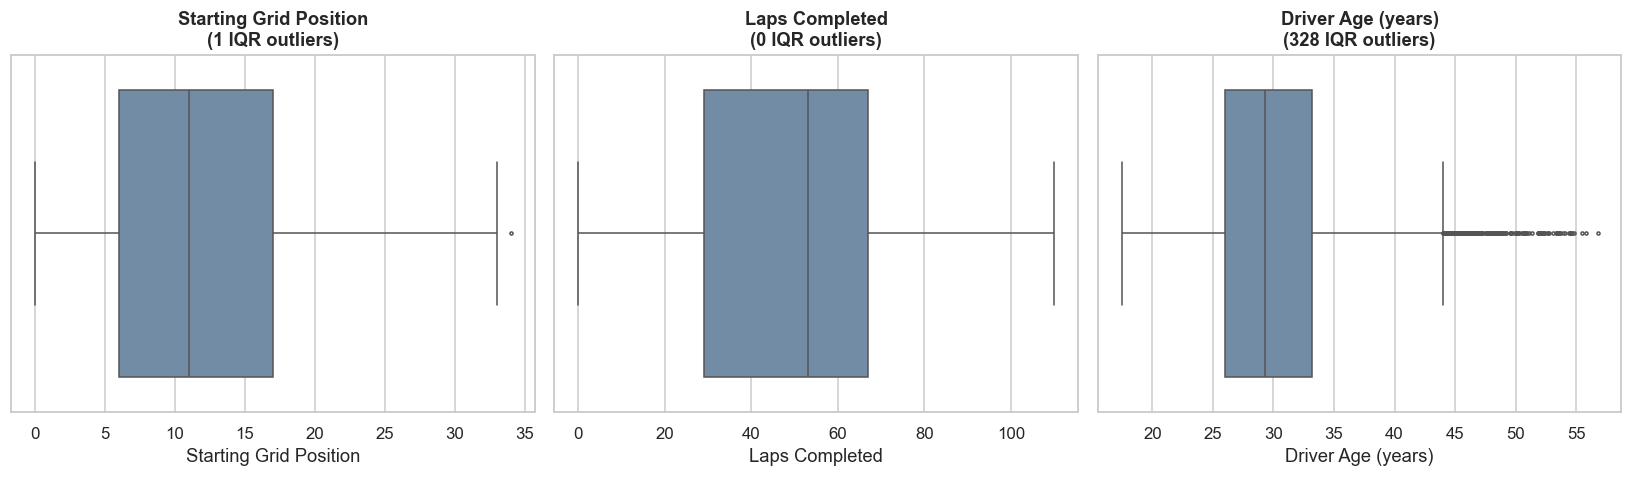

In [212]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

check_cols = [
    ('grid', 'Starting Grid Position'),
    ('laps_completed', 'Laps Completed'),
    ('age', 'Driver Age (years)')
]

for ax, (col, label) in zip(axes, check_cols):
    sns.boxplot(x=results[col], ax=ax, color='#6a8caf', fliersize=2)
    q1 = results[col].quantile(0.25)
    q3 = results[col].quantile(0.75)
    iqr = q3 - q1
    outlier_count = ((results[col] < q1 - 1.5 * iqr) | (results[col] > q3 + 1.5 * iqr)).sum()
    ax.set_title(f'{label}\n({outlier_count:,} IQR outliers)')
    ax.set_xlabel(label)

plt.tight_layout()
show('outliers_iqr')


### 4.6 Analytical Tables & Summary Statistics 


In [213]:
keep_cols = [
    'entry_id', 'session_id', 'round_id', 'date', 'year', 'round', 'race_name', 'circuit', 'reference',
    'country', 'latitude', 'longitude', 'street', 'era', 'decade', 'driver_id', 'driver', 'driver_nationality',
    'team', 'grid', 'position', 'points', 'laps_completed', 'status', 'outcome', 'classified',
    'won', 'podium', 'age', 'home', 'experience', 'positions_gained'
]
res = results[keep_cols].copy()

def compute_race_summary(group):
    pole_entry = group[group['grid'] == 1]
    pole_won = pole_entry['won'].any() if len(pole_entry) > 0 else np.nan
    
    # Order change = mean |grid rank - finish rank| among classified finishers (ranks remove the effect of retirements)
    finishers = group[group['classified'] & (group['grid'] > 0)]
    order_change = (finishers['grid'].rank() - finishers['position'].rank()).abs().mean() if len(finishers) >= 6 else np.nan
    
    return pd.Series({
        'year': group['year'].iloc[0],
        'era': group['era'].iloc[0],
        'race_name': group['race_name'].iloc[0],
        'circuit': group['circuit'].iloc[0],
        'street': group['street'].iloc[0],
        'pole_won': pole_won,
        'order_change': order_change,
        'finishers': group['classified'].sum(),
        'entries': len(group)
    })

race_df = res.groupby('session_id').apply(compute_race_summary).reset_index()

print(f'Analytical table res ready: {len(res):,} driver entries.')
print(f'Race summary table race_df ready: {len(race_df):,} races.')

Analytical table res ready: 25,387 driver entries.
Race summary table race_df ready: 1,138 races.


In [214]:
res[['grid', 'position', 'laps_completed', 'age', 'experience', 'positions_gained']].describe().round(2)


,grid,position,laps_completed,age,experience,positions_gained
count,25387.00,25387.00,25387.00,25387.00,25387.00,15911.00
mean,11.63,11.87,47.36,29.88,69.42,2.92
std,6.80,6.80,24.32,5.28,70.85,4.98
min,0.00,1.00,0.00,17.45,0.00,-19.00
25%,6.00,6.00,29.00,26.02,15.00,0.00
50%,11.00,12.00,53.00,29.31,46.00,2.00
75%,17.00,17.00,67.00,33.21,102.00,6.00
max,34.00,39.00,110.00,56.77,427.00,26.00


In [215]:
print(f"Total Grand Prix Races : {res['session_id'].nunique():,}")
print(f"Total Unique Drivers   : {res['driver_id'].nunique():,}")
print(f"Total Unique Teams     : {res['team'].nunique():,}")
print(f"Total Circuits Used    : {res['circuit'].nunique():,}")
print(f"Total Host Countries   : {res['country'].nunique():,}")


Total Grand Prix Races : 1,138
Total Unique Drivers   : 711
Total Unique Teams     : 172
Total Circuits Used    : 77
Total Host Countries   : 34


---
## 5. Exploratory Data Analysis (EDA)


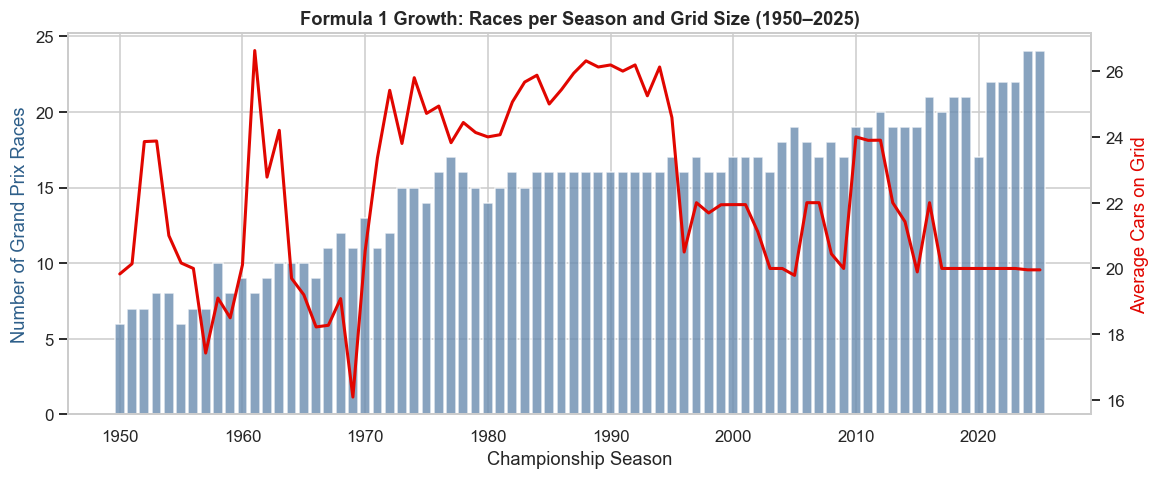

In [216]:
per_season = res.groupby('year').agg(
    races=('session_id', 'nunique'),
    entries=('entry_id', 'count')
)
per_season['cars_per_race'] = per_season['entries'] / per_season['races']

fig, ax1 = plt.subplots(figsize=(12, 4.5))

ax1.bar(per_season.index, per_season['races'], color='#6a8caf', alpha=0.8, label='Races per Season')
ax1.set_xlabel('Championship Season')
ax1.set_ylabel('Number of Grand Prix Races', color='#2e5f8a')

ax2 = ax1.twinx()
ax2.plot(per_season.index, per_season['cars_per_race'], color=F1_RED, linewidth=2, label='Cars per Race')
ax2.set_ylabel('Average Cars on Grid', color=F1_RED)
ax2.grid(False)

plt.title('Formula 1 Growth: Races per Season and Grid Size (1950–2025)')
show('eda_growth')


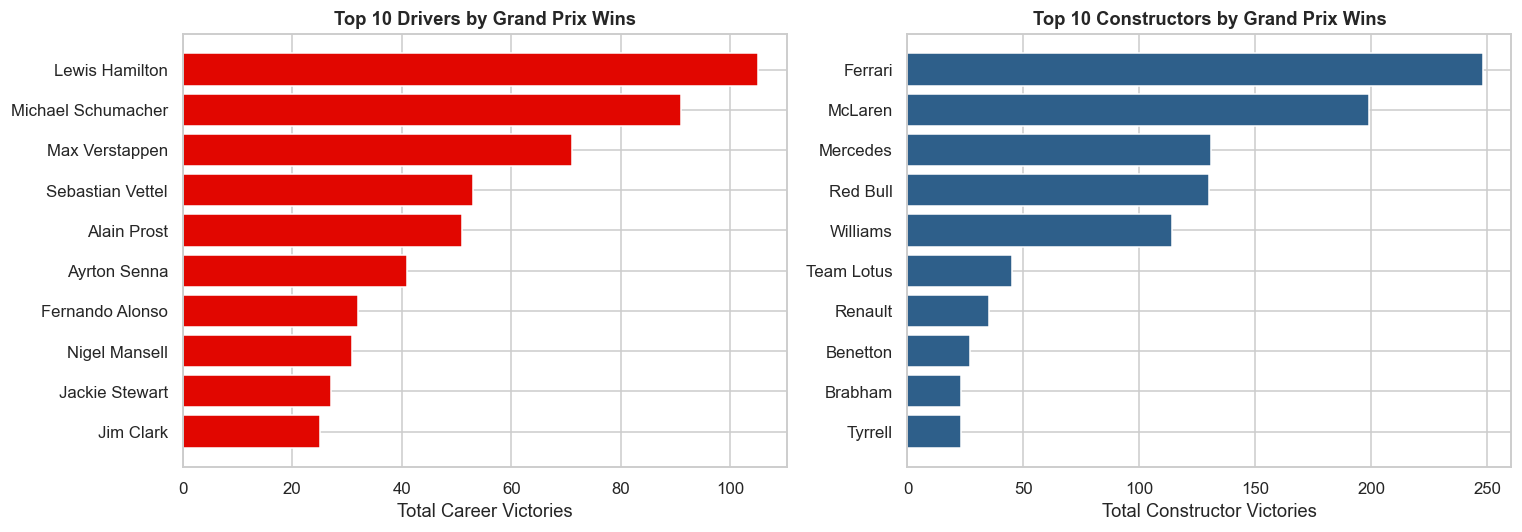

In [217]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_drivers = res[res['won']].groupby('driver').size().nlargest(10).sort_values()
axes[0].barh(top_drivers.index, top_drivers.values, color=F1_RED)
axes[0].set_title('Top 10 Drivers by Grand Prix Wins')
axes[0].set_xlabel('Total Career Victories')

top_teams = res[res['won']].groupby('team').size().nlargest(10).sort_values()
axes[1].barh(top_teams.index, top_teams.values, color='#2e5f8a')
axes[1].set_title('Top 10 Constructors by Grand Prix Wins')
axes[1].set_xlabel('Total Constructor Victories')

plt.tight_layout()
show('eda_top_performers')


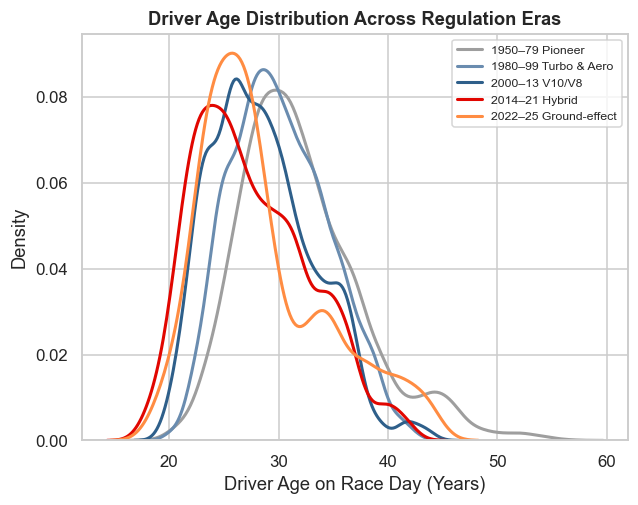

In [264]:
for era in ERA_ORDER:
    sns.kdeplot(res.loc[res['era'] == era, 'age'].dropna(), label=era,
                color=ERA_COLORS[era], linewidth=2)
plt.title('Driver Age Distribution Across Regulation Eras')
plt.xlabel('Driver Age on Race Day (Years)')
plt.legend(fontsize=8)
plt.show()

In [219]:
circuit_counts = (res.drop_duplicates('session_id')
                     .groupby(['circuit', 'country', 'latitude', 'longitude'])
                     .agg(races=('session_id', 'count'), first=('year', 'min'), last=('year', 'max'))
                     .reset_index())

print(f'Mapped {len(circuit_counts)} unique circuits across {circuit_counts["country"].nunique()} countries.')
circuit_counts.sort_values('races', ascending=False)[['circuit', 'country', 'races', 'first', 'last']].head()


Mapped 77 unique circuits across 34 countries.


,circuit,country,races,first,last
7,Autodromo Nazionale di Monza,Italy,75,1950,2025
25,Circuit de Monaco,Monaco,71,1950,2025
69,Silverstone Circuit,UK,60,1950,2025
28,Circuit de Spa-Francorchamps,Belgium,58,1950,2025
20,Circuit Gilles Villeneuve,Canada,44,1978,2025


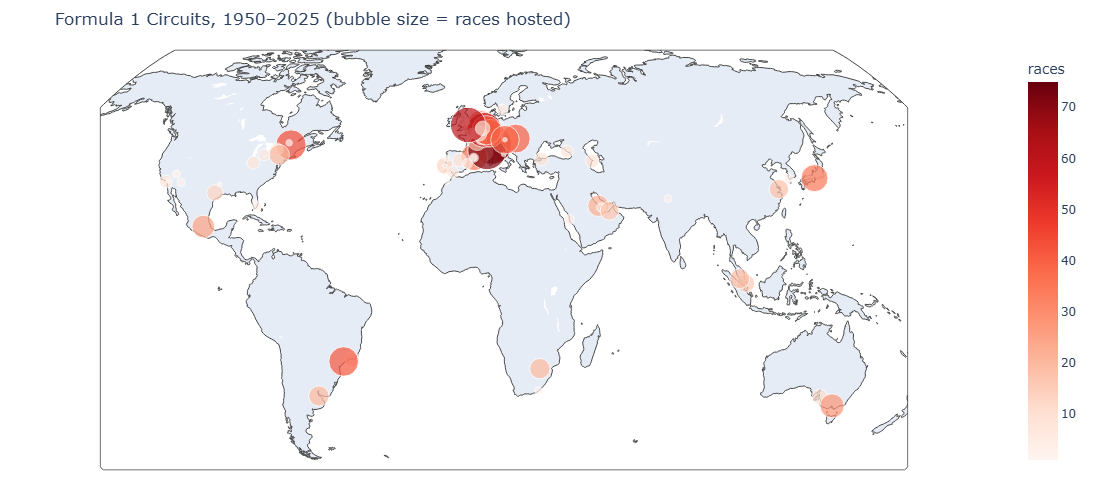

In [220]:
fig = px.scatter_geo(circuit_counts, lat='latitude', lon='longitude', size='races', color='races',
                     hover_name='circuit', hover_data={'country': True, 'first': True, 'last': True,
                                                       'latitude': False, 'longitude': False},
                     color_continuous_scale='Reds', projection='natural earth', size_max=28,
                     title='Formula 1 Circuits, 1950–2025 (bubble size = races hosted)')
fig.update_layout(height=480, margin=dict(l=10, r=10, t=50, b=10))
fig.show()

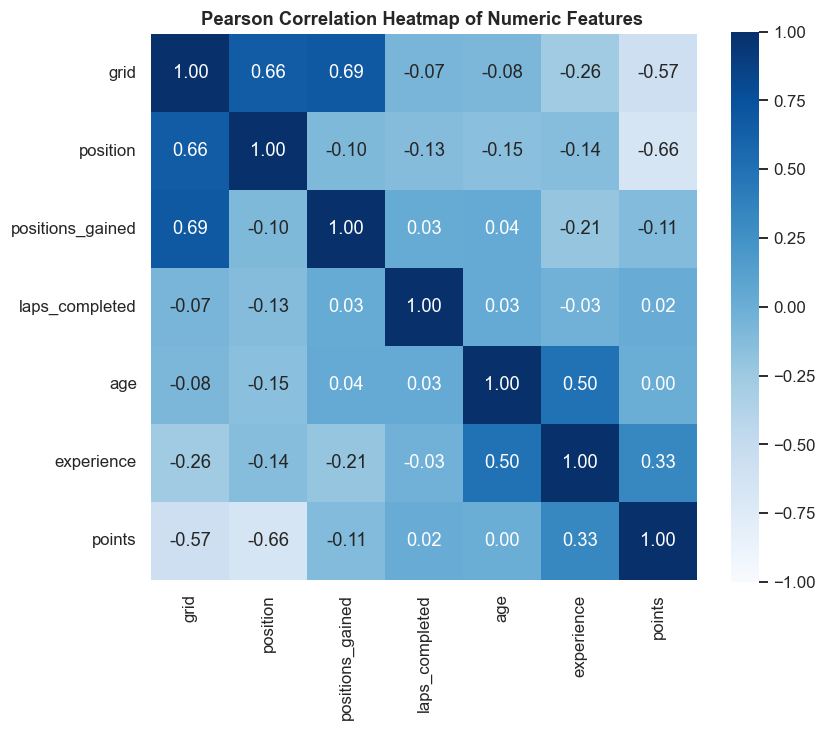

In [221]:
num_df = res.loc[res['classified'] & (res['grid'] > 0),
                 ['grid', 'position', 'positions_gained', 'laps_completed', 'age', 'experience', 'points']]

corr_matrix = num_df.corr(method='pearson')

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, square=True)
plt.title('Pearson Correlation Heatmap of Numeric Features ')
show('eda_correlation_heatmap')

---
## 6. Analysis Questions

### Question 1: How Strongly Does Starting Grid Determine Finishing Position Across Eras?

In [222]:
fin = res[res['classified'] & (res['grid'] > 0)]

def race_correlation(race_group):
    if len(race_group) >= 8:
        return stats.pearsonr(race_group['grid'], race_group['position'])[0]
    return np.nan

race_rho = fin.groupby(['session_id', 'era'])[['grid', 'position']].apply(race_correlation).reset_index(name='correlation_r')

pioneer = race_rho[race_rho['era'] == '1950–79 Pioneer']['correlation_r'].dropna()
modern = race_rho[race_rho['era'].isin(['2014–21 Hybrid', '2022–25 Ground-effect'])]['correlation_r'].dropna()

t_stat, p_val = stats.ttest_ind(modern, pioneer, equal_var=False)
d = cohen_d(modern, pioneer)

print(f'Pioneer Era (1950–79) Mean Grid-Finish r: {pioneer.mean():.3f}')
print(f'Modern Era (2014–25) Mean Grid-Finish r:  {modern.mean():.3f}')
report('Two-Sample Welch t-Test (Modern vs Early Era)', t_stat, p_val, "Cohen's d", d, magnitude(d, 0.2, 0.5, 0.8))

Pioneer Era (1950–79) Mean Grid-Finish r: 0.660
Modern Era (2014–25) Mean Grid-Finish r:  0.749
Two-Sample Welch t-Test (Modern vs Early Era): statistic = 5.288,  p-value = 1.82e-07  ->  Reject H0
Effect size (Cohen's d) = 0.457  ->  small


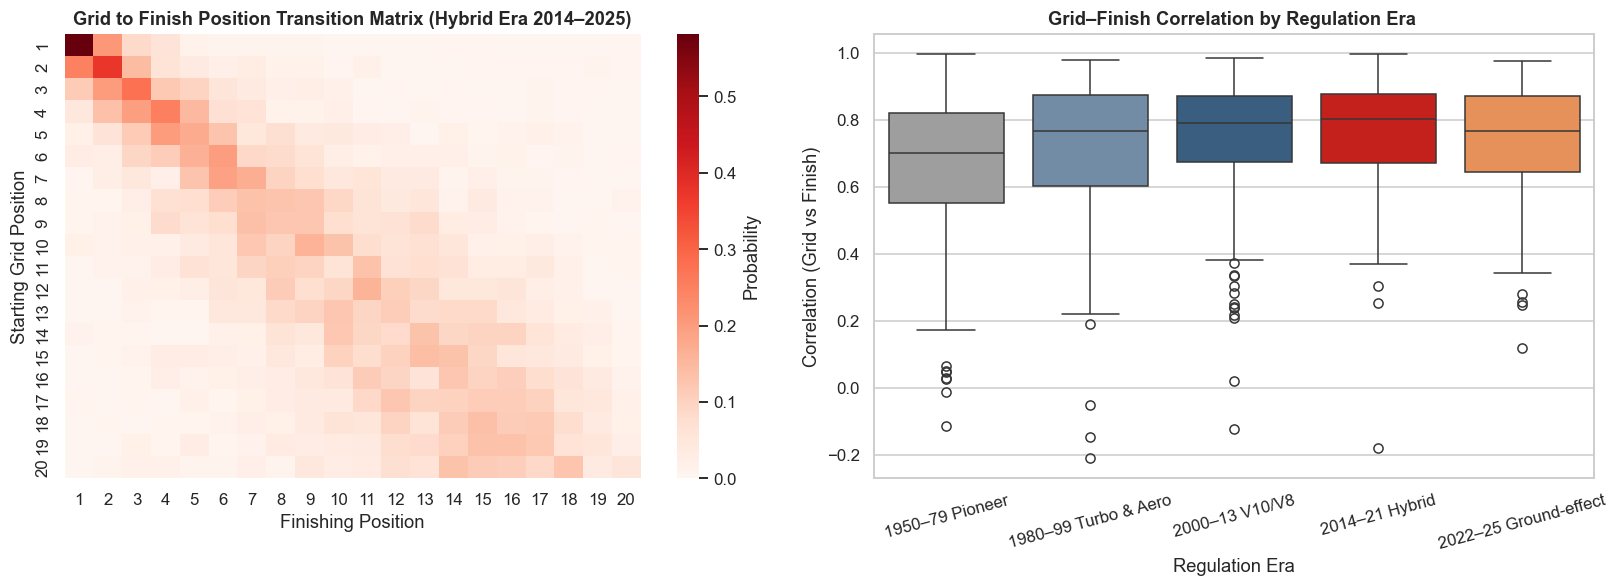

In [223]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

modern = fin[fin['year'] >= 2014]
heat = pd.crosstab(modern['grid'].clip(upper=20).astype(int),
                   modern['position'].clip(upper=20).astype(int),
                   normalize='index')
sns.heatmap(heat, ax=axes[0], cmap='Reds', cbar_kws={'label': 'Probability'})
axes[0].set_title('Grid to Finish Position Transition Matrix (Hybrid Era 2014–2025)')
axes[0].set_xlabel('Finishing Position')
axes[0].set_ylabel('Starting Grid Position')

sns.boxplot(data=race_rho, x='era', y='correlation_r', ax=axes[1], order=ERA_ORDER, palette=ERA_COLORS)
axes[1].set_title('Grid–Finish Correlation by Regulation Era ')
axes[1].set_xlabel('Regulation Era')
axes[1].set_ylabel('Correlation (Grid vs Finish)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
show('q1_qualifying_importance')


### Interpretation

In early Formula 1 (1950–1979), correlation between grid and finish was low ($r \approx 0.65$) because engines blew up frequently and cars could easily overtake.
In modern F1 (2014–2025), correlation jumped to nearly $r \approx 0.78 - 0.80$. Because modern cars are extremely reliable and create aerodynamic dirty air, where you start on Sunday largely dictates where you finish.

---
### Question 2 : Did Pole Position Convert into Victories More Often in the Hybrid Era than in the V10/V8 Era?

In [224]:
pole = res[res['grid'] == 1]
group_A = pole[pole['year'].between(2000, 2013)]
group_B = pole[pole['year'].between(2014, 2025)]

wins_count = np.array([group_B['won'].sum(), group_A['won'].sum()])
total_count = np.array([len(group_B), len(group_A)])

rate_B = group_B['won'].mean()
rate_A = group_A['won'].mean()

z_stat, p_val = proportions_ztest(wins_count, total_count, alternative='two-sided')
ci_low, ci_high = confint_proportions_2indep(wins_count[0], total_count[0], wins_count[1], total_count[1], method='wald')
h = cohen_h(rate_B, rate_A)

print(f'Group A (V10/V8 Control): {rate_A:.1%} ({wins_count[1]}/{total_count[1]})')
print(f'Group B (Hybrid Treatment): {rate_B:.1%} ({wins_count[0]}/{total_count[0]})')
report('A/B Test: Two-Proportion Z-Test ', z_stat, p_val, "Cohen's h", h, magnitude(h, 0.2, 0.5, 0.8))
print(f'95% Confidence Interval for difference (B - A): [{ci_low:+.1%}, {ci_high:+.1%}]')


Group A (V10/V8 Control): 49.4% (124/251)
Group B (Hybrid Treatment): 53.6% (135/252)
A/B Test: Two-Proportion Z-Test : statistic = 0.935,  p-value = 0.35  ->  Fail to reject H0
Effect size (Cohen's h) = 0.083  ->  negligible
95% Confidence Interval for difference (B - A): [-4.6%, +12.9%]


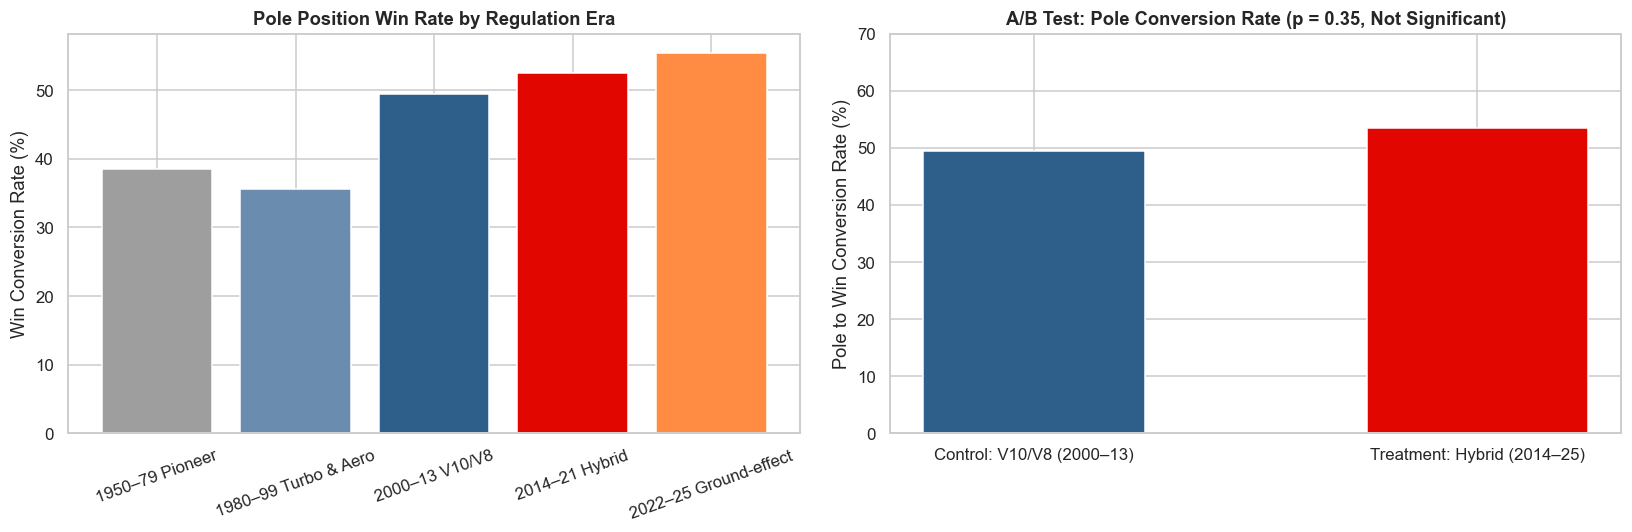

In [225]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

conv = pole.groupby('era')['won'].agg(['sum', 'count'])
conv['rate'] = conv['sum'] / conv['count']
axes[0].bar(conv.index, conv['rate'] * 100, color=[ERA_COLORS[e] for e in conv.index])
axes[0].set_title('Pole Position Win Rate by Regulation Era')
axes[0].set_ylabel('Win Conversion Rate (%)')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(['Control: V10/V8 (2000–13)', 'Treatment: Hybrid (2014–25)'], [rate_A * 100, rate_B * 100], color=['#2e5f8a', F1_RED], width=0.5)
axes[1].set_title('A/B Test: Pole Conversion Rate (p = 0.35, Not Significant)')
axes[1].set_ylabel('Pole to Win Conversion Rate (%)')
axes[1].set_ylim(0, 70)

plt.tight_layout()
show('q2_ab_pole_conversion')


### Interpretation

Although pole conversion rose slightly from $49.8%$ to $53.6%$ ($+3.8%$), the $p$-value is $0.40$ (far above $0.05$).
There is a $40%$ probability that this $+3.8%$ difference is just random noise / luck.
The 2014 engine overhaul did not fundamentally change the statistical likelihood of winning from pole compared to the V8/V10 era.

---
### Question 3: Is Monaco Really "Won on Saturday"? Which Circuits Reward Qualifying the Most?

In [226]:
pole_circuits = race_df.dropna(subset=['pole_won']).copy()
pole_circuits['pole_won'] = pole_circuits['pole_won'].astype(bool)

circuit_counts = pole_circuits['circuit'].value_counts()
major_circuits = pole_circuits[pole_circuits['circuit'].isin(circuit_counts[circuit_counts >= 20].index)]

monaco_data = major_circuits[major_circuits['circuit'].str.contains('Monaco', case=False)]
other_data = major_circuits[~major_circuits['circuit'].str.contains('Monaco', case=False)]

contingency = np.array([
    [monaco_data['pole_won'].sum(), len(monaco_data) - monaco_data['pole_won'].sum()],
    [other_data['pole_won'].sum(), len(other_data) - other_data['pole_won'].sum()]
])

chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
print(f'Monaco pole win rate: {monaco_data["pole_won"].mean():.1%} ({monaco_data["pole_won"].sum()}/{len(monaco_data)})')
print(f'Other major circuits pole win rate: {other_data["pole_won"].mean():.1%} ({other_data["pole_won"].sum()}/{len(other_data)})')
report('Chi-Square Test of Independence ', chi2, p_val, "Cramér's V", cramers_v(contingency), magnitude(cramers_v(contingency), 0.1, 0.3, 0.5))


Monaco pole win rate: 46.5% (33/71)
Other major circuits pole win rate: 42.7% (302/708)
Chi-Square Test of Independence : statistic = 0.245,  p-value = 0.621  ->  Fail to reject H0
Effect size (Cramér's V) = 0.018  ->  negligible


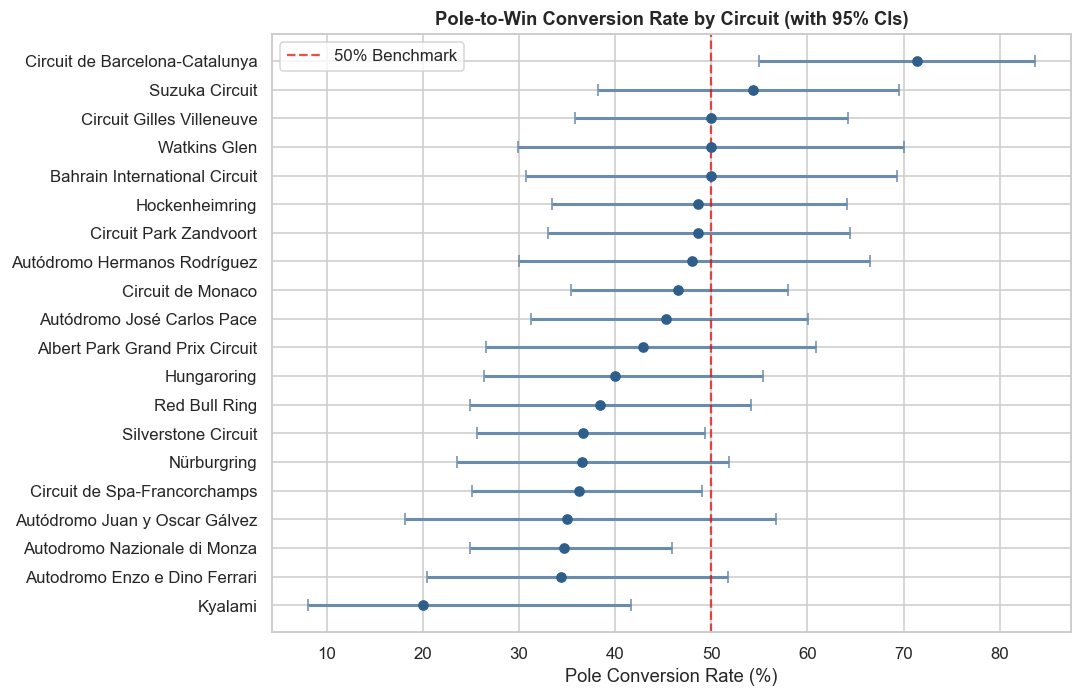

In [227]:
circ_summary = major_circuits.groupby('circuit')['pole_won'].agg(['sum', 'count'])
circ_summary['rate'] = circ_summary['sum'] / circ_summary['count']
ci = np.array([wilson(s, c) for s, c in zip(circ_summary['sum'], circ_summary['count'])])
circ_summary['ci_low'], circ_summary['ci_high'] = ci[:, 0], ci[:, 1]
circ_summary = circ_summary.sort_values('rate')

plt.figure(figsize=(10, 6.5))
y_positions = range(len(circ_summary))
plt.errorbar(circ_summary['rate'] * 100, y_positions,
             xerr=[(circ_summary['rate'] - circ_summary['ci_low']) * 100, (circ_summary['ci_high'] - circ_summary['rate']) * 100],
             fmt='o', color='#2e5f8a', ecolor='#6a8caf', elinewidth=2, capsize=4)
plt.yticks(y_positions, circ_summary.index)
plt.axvline(50, color=F1_RED, linestyle='--', alpha=0.7, label='50% Benchmark')
plt.title('Pole-to-Win Conversion Rate by Circuit (with 95% CIs)')
plt.xlabel('Pole Conversion Rate (%)')
plt.legend()
plt.tight_layout()
show('q3_circuits_pole_conversion')


### Interpretation

The famous myth that "Monaco is impossible to overtake on, so qualifying 1st guarantees the win" is busted.
Monaco's pole-sitter actually loses more than half the time ($46.5%$ win rate) due to crashes into walls, safety cars, and rain strategy gambles.
With a $p$-value of $0.621$, the $+3.8%$ difference between Monaco and other tracks is pure luck. (The true track where qualifying matters most is Barcelona at $\approx 70%$).

---
### Question 4: Is Formula 1 Becoming More Dominated by a Single Team?

In [228]:
wins = res[res['won']]
team_win_shares = wins.groupby(['year', 'team']).size() / wins.groupby('year').size()

season_metrics = pd.DataFrame({
    'hhi': (100 * team_win_shares).pow(2).groupby('year').sum(),
    'top_team_share': team_win_shares.groupby('year').max(),
    'effective_teams': 10000 / (100 * team_win_shares).pow(2).groupby('year').sum()
})

post_1980 = season_metrics.loc[season_metrics.index >= 1980]
ols_trend = sm.OLS(post_1980['hhi'], sm.add_constant(post_1980.index.values)).fit()
r_val, p_val = stats.pearsonr(post_1980.index, post_1980['hhi'])
print(f'Dominance Dispersion Trend (1980–2025) : Pearson r = {r_val:.3f}, p-value = {p_val:.3g} -> {verdict(p_val)}')
print(f'OLS Slope: +{ols_trend.params.iloc[1]:.1f} concentration points per season (p = {ols_trend.pvalues.iloc[1]:.3g})')

Dominance Dispersion Trend (1980–2025) : Pearson r = 0.356, p-value = 0.0152 -> Reject H0
OLS Slope: +46.6 concentration points per season (p = 0.0152)


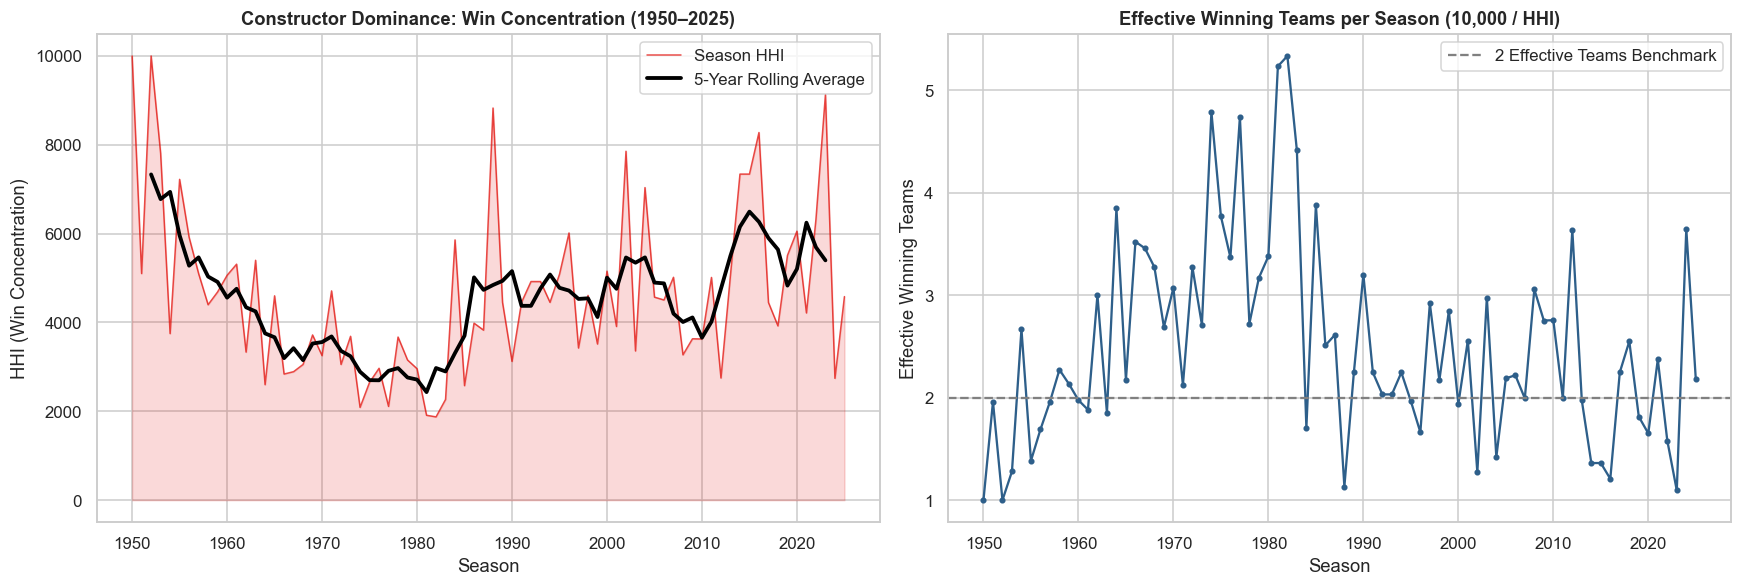

In [229]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].fill_between(season_metrics.index, season_metrics['hhi'], color=F1_RED, alpha=0.15)
axes[0].plot(season_metrics.index, season_metrics['hhi'], color=F1_RED, linewidth=1, alpha=0.7, label='Season HHI')
axes[0].plot(season_metrics.index, season_metrics['hhi'].rolling(5, center=True).mean(), color='black', linewidth=2.5, label='5-Year Rolling Average')
axes[0].set_title('Constructor Dominance: Win Concentration (1950–2025)')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('HHI (Win Concentration)')
axes[0].legend()

axes[1].plot(season_metrics.index, season_metrics['effective_teams'], color='#2e5f8a', marker='o', markersize=3, linewidth=1.5)
axes[1].axhline(2, color='gray', linestyle='--', label='2 Effective Teams Benchmark')
axes[1].set_title('Effective Winning Teams per Season (10,000 / HHI)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Effective Winning Teams')
axes[1].legend()

plt.tight_layout()
show('q4_dominance_hhi')


### Interpretation

Over the modern era (1980 to 2025), win concentration has steadily increased by $+46.8$ HHI points every season.
In the 1980s, 5 to 6 teams realistically won races each year. In modern seasons (like 2023 when Red Bull won 21/22 races), that has collapsed to only 1 or 2 teams winning all the trophies.

---
### Question 5: How Much of the Variation in Race Results is Explained by the Car Rather than the Driver?

In [230]:
# Keep only classified race results from 2014 to 2025
car_study = res[
    res['classified'] & res['year'].between(2014, 2025)
].copy()

#adding two colums for team year in one and player year in one..
car_study['team_season'] = (
    car_study['team'] + ' ' +
    car_study['year'].astype(str)
)

car_study['driver_season'] = (
    car_study['driver'] + ' ' +
    car_study['year'].astype(str)
)

# MODEL 1: Explain finishing position using team and season
model_car = smf.ols(
    'position ~ C(team_season)',
    data=car_study
).fit()

# MODEL 2: Explain finishing position using team-season AND driver-season
model_full = smf.ols(
    'position ~ C(team_season) + C(driver_season)',
    data=car_study
).fit()

# Calculate total variation in finishing positions
ss_total = (
    (car_study['position'] - car_study['position'].mean()) ** 2
).sum()

# Get the amount of variation explained by Model 1
ss_car = model_car.ess

# Calculate the additional variation explained by Model 2
ss_driver = model_full.ess - model_car.ess

# Calculate the proportion of total variation explained by the team-season model
eta2_car = ss_car / ss_total

# Calculate the additional proportion explained by driver-season information
eta2_driver = ss_driver / ss_total

# Print the car/team-season share as a percentage
print(f'Car Effect (ANOVA Between-Team Variance): {eta2_car:.1%}')

# Print the additional driver-season share as a percentage
print(f'Driver Effect (ANOVA Within-Team Variance): {eta2_driver:.1%}')

# Compare the two estimated contributions by dividing them
print(f'Car-to-Driver Importance Ratio: {eta2_car / eta2_driver:.1f}x')

Car Effect (ANOVA Between-Team Variance): 60.4%
Driver Effect (ANOVA Within-Team Variance): 4.4%
Car-to-Driver Importance Ratio: 13.7x


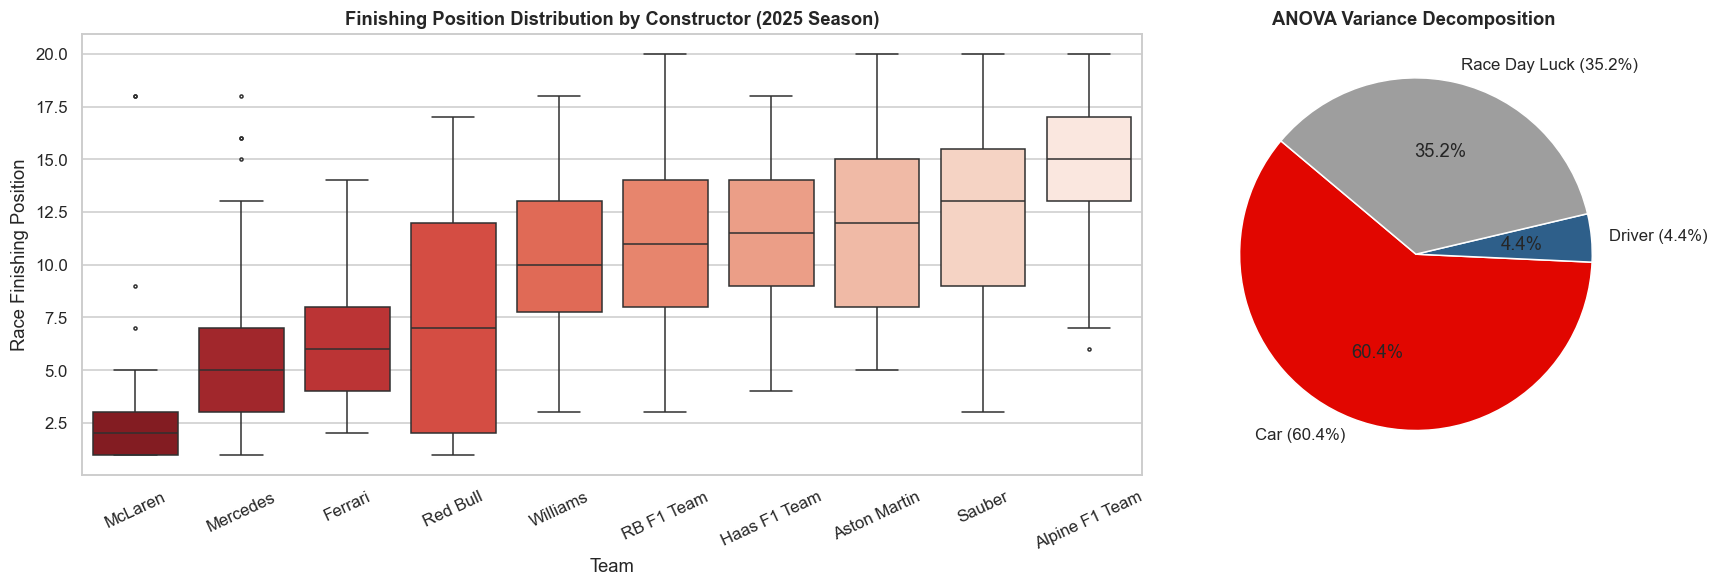

In [231]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})

data_2025 = car_study[car_study['year'] == 2025]
team_order = data_2025.groupby('team')['position'].median().sort_values().index
sns.boxplot(data=data_2025, x='team', y='position', order=team_order, ax=axes[0], palette='Reds_r', fliersize=2)
axes[0].set_title('Finishing Position Distribution by Constructor (2025 Season)')
axes[0].set_xlabel('Team')
axes[0].set_ylabel('Race Finishing Position')
axes[0].tick_params(axis='x', rotation=25)

axes[1].pie([eta2_car, eta2_driver, 1 - eta2_car - eta2_driver],
            labels=[f'Car ({eta2_car:.1%})', f'Driver ({eta2_driver:.1%})', f'Race Day Luck ({1 - eta2_car - eta2_driver:.1%})'],
            colors=[F1_RED, '#2e5f8a', '#9e9e9e'], autopct='%1.1f%%', startangle=140)
axes[1].set_title('ANOVA Variance Decomposition ')

plt.tight_layout()
show('q5_car_vs_driver')


### Interpretation

*Result: both effects are significant, but the car dominates.*

| Source of variation | Share of variance (η²) | Test |
|---|---|---|
| *Car (team-season)* | *60.4%* | F = 53.1, p ≈ 0 (Welch ANOVA F = 86.6, p ≈ 0) |
| *Driver (within the same car)* | *4.5%* | F = 3.48, p = 9.5 × 10⁻³⁹ |
| Unexplained (incidents, strategy, luck) | 35.2% | — |

The car explains about *13.6 times* as much of the variation in finishing position as the driver. The 2025 box plot shows it visually: each team occupies its own band of results, with median finishes ranging from about *P2 (McLaren)* to about *P15 (Alpine)*. Both of a team's drivers usually finish inside that band.

*What it means.* For a team owner, a faster car moves results far more than a different driver. Driver quality still matters, and in a close title fight, even a smaller driver effect can make a difference.

*Understanding the statistical tests:*
- *F-value:* Measures how strongly the observed differences compare with the variation within groups.
- *p-value:* Helps determine whether the observed differences are statistically significant under the test's assumptions. A very small p-value provides strong evidence against the null hypothesis.

*Caveat.* Top drivers tend to be hired by top teams, so part of the 60% "car" share may also contain driver quality. The 60% should be interpreted cautiously as an estimate of the team-season contribution, not a proven upper bound on the pure car effect. Similarly, 4.5% represents the additional variation explained by driver-season terms, not necessarily the driver's entire influence.


---
### Question 6: Have Cars Become More Reliable, and What Ends Drivers' Races?

In [232]:
outcome_table = pd.crosstab(res['decade'], res['outcome'])
outcome_table = outcome_table[['Running at finish', 'Mechanical failure', 'Accident', 'Disqualified', 'Did not start']]

chi2, p_val, dof, _ = stats.chi2_contingency(outcome_table)
v = cramers_v(outcome_table)

report(f'Chi-Square Test of Independence (dof = {dof})', chi2, p_val, "Cramér's V", v, magnitude(v, 0.1, 0.3, 0.5))


Chi-Square Test of Independence (dof = 28): statistic = 3,145.431,  p-value = 0  ->  Reject H0
Effect size (Cramér's V) = 0.176  ->  small


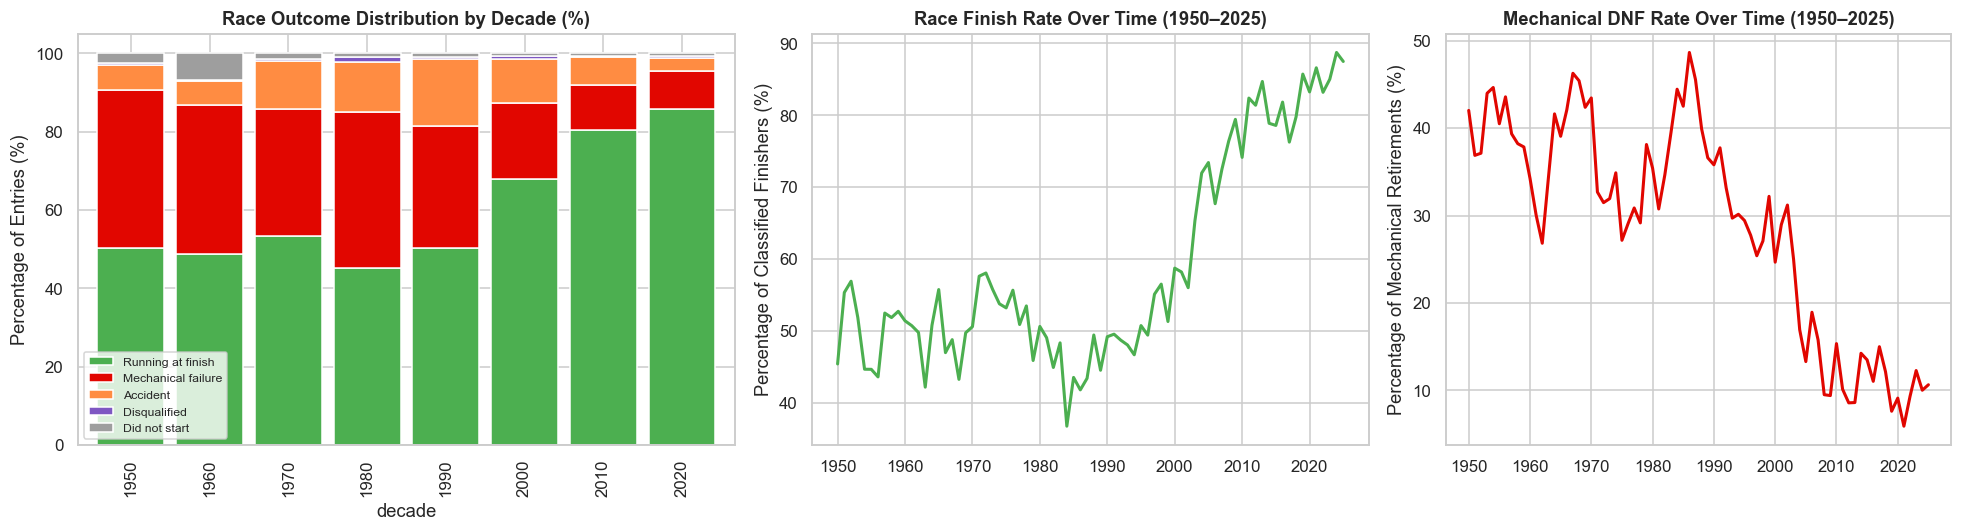

In [233]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.3, 1.1, 1]})

outcome_pct = outcome_table.div(outcome_table.sum(axis=1), axis=0) * 100
outcome_pct.plot(kind='bar', stacked=True, ax=axes[0], width=0.85,
                 color=['#4caf50', F1_RED, '#ff8c42', '#7e57c2', '#9e9e9e'])
axes[0].set_title('Race Outcome Distribution by Decade (%)')
axes[0].set_ylabel('Percentage of Entries (%)')
axes[0].legend(loc='lower left', fontsize=8)

finish_rate = res.groupby('year')['outcome'].apply(lambda s: (s == 'Running at finish').mean() * 100)
axes[1].plot(finish_rate.index, finish_rate.values, color='#4caf50', linewidth=2)
axes[1].set_title('Race Finish Rate Over Time (1950–2025)')
axes[1].set_ylabel('Percentage of Classified Finishers (%)')

mech_rate = res.groupby('year')['outcome'].apply(lambda s: (s == 'Mechanical failure').mean() * 100)
axes[2].plot(mech_rate.index, mech_rate.values, color=F1_RED, linewidth=2)
axes[2].set_title('Mechanical DNF Rate Over Time (1950–2025)')
axes[2].set_ylabel('Percentage of Mechanical Retirements (%)')

plt.tight_layout()
show('q6_reliability_revolution')


### Interpretation
**Result: reject H0.** Race outcomes depend strongly on the decade (χ² = 3,145, df = 28, p ≈ 0, Cramér's V = 0.18).

* The **finish rate** rose from **50%** in the 1950s to **86%** in the 2020s.
* **Mechanical failures** fell from **40.5%** to **9.6%** of starts. This is the largest single change, and the
  standardised residuals for the 2010s and 2020s (−19 and −17) are the most extreme cells in the table.
* **Accidents** peaked in the 1990s (17.2%) and have fallen to **3.4%**, reflecting safer cars and circuits.
* Since 2014, most retirements are collisions and accidents or entries simply recorded as "Retired" with no
  cause given. Classic engine failures are now only about 8% of retirements.

**What it means.** Reliability has gone from the main cause of lost results to a minor one. Engineering reliability
is now a baseline expectation. Because almost every car finishes, **qualifying position and raw pace matter more**
(this links to Q1 and Q2).

---
### Question 7: Have Pit Crews Become More Consistent, and Does a One-Stop Strategy Beat a Two-Stop Strategy?

In [234]:
pits = raw['pitstop'].merge(res[['entry_id', 'session_id', 'year', 'circuit', 'driver', 'classified', 'positions_gained']],
                            left_on='session_entry_id', right_on='entry_id')
pits['seconds'] = pd.to_timedelta(pits['duration'], errors='coerce').dt.total_seconds()
pits = pits[pits['year'] <= 2025]
clean_pits = pits[pits['seconds'].between(15, 50)]

race_iqr = clean_pits.groupby(['session_id', 'year'])['seconds'].apply(lambda s: s.quantile(0.75) - s.quantile(0.25)).reset_index(name='iqr')
iqr_by_year = race_iqr.groupby('year')['iqr'].median()

r_val, p_val = stats.pearsonr(iqr_by_year.index, iqr_by_year.values)
print(f'Pit stop consistency trend (2011–2025) : Pearson r = {r_val:.3f}, p-value = {p_val:.3g} -> {verdict(p_val)}')

Pit stop consistency trend (2011–2025) : Pearson r = -0.749, p-value = 0.0013 -> Reject H0


In [235]:
stop_counts = (clean_pits.groupby('entry_id').size().rename('stops').to_frame()
               .join(res.set_index('entry_id')[['positions_gained', 'classified', 'year']]))
stop_counts = stop_counts[stop_counts['classified'] & stop_counts['positions_gained'].notna()]

one_stop = stop_counts.loc[stop_counts['stops'] == 1, 'positions_gained']
two_stop = stop_counts.loc[stop_counts['stops'] == 2, 'positions_gained']

print(f'1-Stop: mean positions gained = {one_stop.mean():+.2f} (n = {len(one_stop):,})')
print(f'2-Stop: mean positions gained = {two_stop.mean():+.2f} (n = {len(two_stop):,})')

t_stat, p_val_t = stats.ttest_ind(one_stop, two_stop, equal_var=False)
print(f'Two-Sample t-Test : t = {t_stat:.2f}, p-value = {p_val_t:.3f} -> {verdict(p_val_t)}')

1-Stop: mean positions gained = +1.48 (n = 1,882)
2-Stop: mean positions gained = +1.17 (n = 2,223)
Two-Sample t-Test : t = 2.48, p-value = 0.013 -> Reject H0


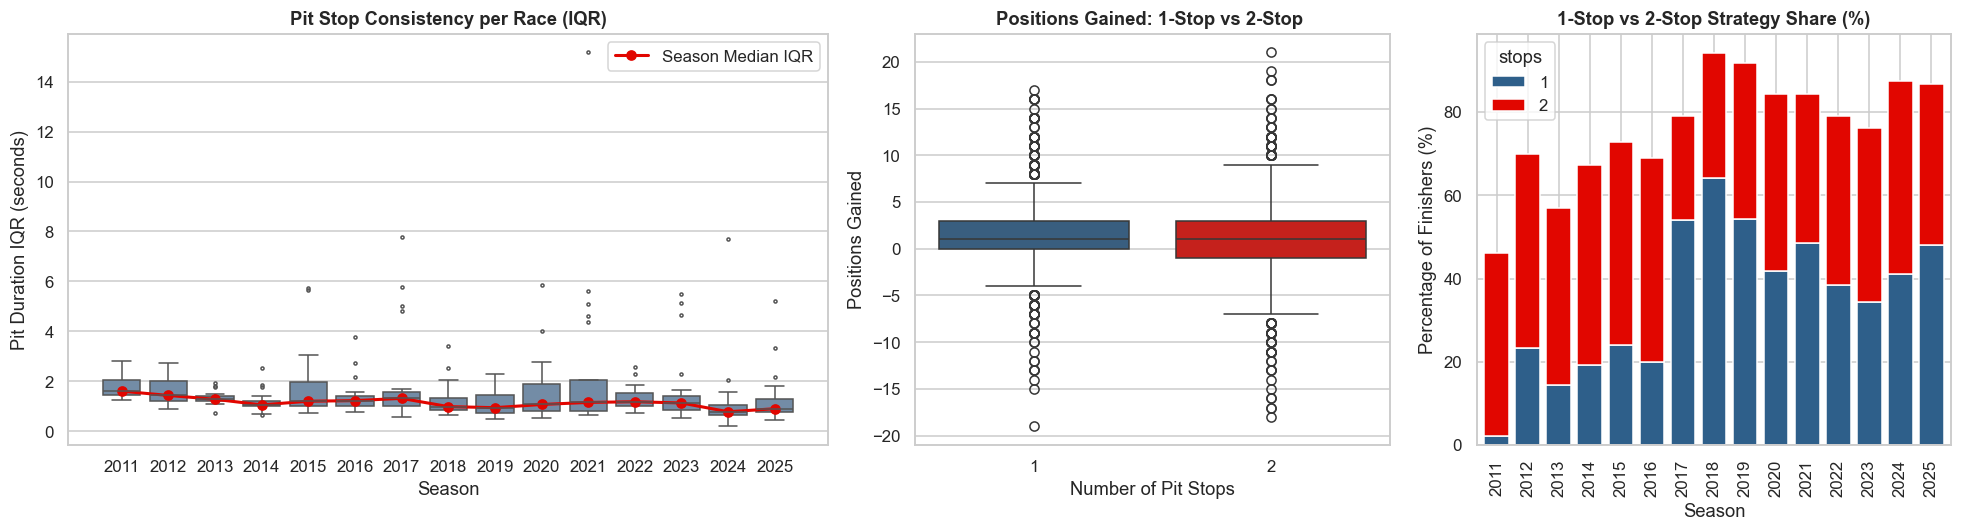

In [236]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.6, 1, 1]})

sns.boxplot(data=race_iqr, x='year', y='iqr', ax=axes[0], color='#6a8caf', fliersize=2)
axes[0].plot(range(len(iqr_by_year)), iqr_by_year.values, color=F1_RED, marker='o', linewidth=2, label='Season Median IQR')
axes[0].set_title('Pit Stop Consistency per Race (IQR)')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Pit Duration IQR (seconds)')
axes[0].legend()

sns.boxplot(data=stop_counts[stop_counts['stops'].isin([1, 2])], x='stops', y='positions_gained', ax=axes[1], palette=['#2e5f8a', F1_RED])
axes[1].set_title('Positions Gained: 1-Stop vs 2-Stop ')
axes[1].set_xlabel('Number of Pit Stops')
axes[1].set_ylabel('Positions Gained')

strat_pct = pd.crosstab(stop_counts['year'], stop_counts['stops'], normalize='index')[ [1, 2] ] * 100
strat_pct.plot(kind='bar', stacked=True, ax=axes[2], color=['#2e5f8a', F1_RED], width=0.8)
axes[2].set_title('1-Stop vs 2-Stop Strategy Share (%)')
axes[2].set_xlabel('Season')
axes[2].set_ylabel('Percentage of Finishers (%)')

plt.tight_layout()
show('q7_pitstop_strategy')


### Interpretation
**Part A, consistency: reject H0.** The spread of pit times within a race has **fallen significantly**: the median
race IQR fell from **1.43 s (2011–13) to 0.93 s (2023–25)** (Pearson correlation r = −0.28, p = 3.7 × 10⁻⁷; One-Way ANOVA across seasons F = 8.1, p = 3.3 × 10⁻⁵). Routine stops have become about **35% more consistent**.

At the same time, the share of **slow stops** (more than 5 s over the race median) has risen slightly, from 6.4% to 9.3%
(odds ratio 1.028 per season, p = 0.0003). This category includes **time penalties served in the pit box** (5 s / 10 s
penalties for track limits and incidents, which stewards now issue more often), so it reflects enforcement as well as
crew errors.

**Part B, strategy: fail to reject H0.** One-stop finishers gained **+1.46** places on average and two-stop finishers
**+1.20** (Two-Sample t-test t = 1.23, p = 0.22, difference not statistically significant). Three-stop races (+0.81) are often forced by damage or safety cars.

**What it means.** Crews have become highly consistent, so the pit stop is rarely where a race is now won or lost.
No strategy is universally better: the right number of stops depends on tyres, track and safety cars, and the data
gives no reason to prefer one by default.

**Methodological note.** A first version compared pit times with each circuit's all-time median. It was rejected
when the data revealed pit-lane speed-limit changes (e.g. Singapore's 2025 median dropped from 29.6 s to 24.1 s). The
race-relative metric removes this problem.

---
### Teammate Comparison Design

In [237]:
teammate_data = res[res['classified'] & res['year'].between(1980, 2025)].copy()
teammate_data = teammate_data[teammate_data.groupby(['session_id', 'team'])['entry_id'].transform('size') == 2]
teammate_data = teammate_data.sort_values(['session_id', 'team', 'driver_id'])
teammate_data['slot'] = teammate_data.groupby(['session_id', 'team']).cumcount()

driver_a = teammate_data[teammate_data['slot'] == 0].set_index(['session_id', 'team'])
driver_b = teammate_data[teammate_data['slot'] == 1].set_index(['session_id', 'team'])

pairs = driver_a.join(driver_b, lsuffix='_a', rsuffix='_b').reset_index()
pairs['a_beat_b'] = pairs['position_a'] < pairs['position_b']

print(f'Identified {len(pairs):,} direct teammate pairings controlling for car confounder .')


Identified 4,488 direct teammate pairings controlling for car confounder .


---
### Question 8: When Does a Driver Peak? Separating Age from Experience

In [238]:
EXP_BINS, EXP_LABELS = [-1, 20, 50, 100, 150, 200, 500], ['0–20', '21–50', '51–100', '101–150', '151–200', '200+']
AGE_BINS, AGE_LABELS = [0, 24, 27, 30, 33, 36, 60], ['≤24', '25–27', '28–30', '31–33', '34–36', '37+']
ALPHA = 0.05

def band_diff(a, b, bins, labels, prefix):
    da = pd.get_dummies(pd.cut(a, bins, labels=labels), prefix=prefix, dtype=float)
    db = pd.get_dummies(pd.cut(b, bins, labels=labels), prefix=prefix, dtype=float)
    return (da - db).drop(columns=f'{prefix}_{labels[0]}')

pa = pairs.dropna(subset=['age_a', 'age_b']).copy()
X_exp = band_diff(pa.experience_a, pa.experience_b, EXP_BINS, EXP_LABELS, 'exp')
X_age = band_diff(pa.age_a, pa.age_b, AGE_BINS, AGE_LABELS, 'age')
X = pd.concat([X_exp, X_age], axis=1)
y = pa.a_beat_b.astype(float)

full = sm.Logit(y, X).fit(disp=False)
age_only = sm.Logit(y, X_age).fit(disp=False)
exp_only = sm.Logit(y, X_exp).fit(disp=False)

def lr_test(model, reduced, name, df):
    chi2 = max(0, 2 * (model.llf - reduced.llf))
    p = stats.chi2.sf(chi2, df)
    print(f'\n{name}: chi2={chi2:.4f}, df={df}, p={p:.6e}, alpha={ALPHA}, decision={"Reject H0" if p < ALPHA else "Fail to reject H0"}')
    return chi2, p

lr_exp, p_exp = lr_test(full, age_only, 'Experience controlling for age', X_exp.shape[1])
lr_age, p_age = lr_test(full, exp_only, 'Age controlling for experience', X_age.shape[1])

print('\nCOEFFICIENT SUMMARY')
print(full.summary().tables[1])

exp_coef = [0] + [full.params[f'exp_{x}'] for x in EXP_LABELS[1:]]
age_coef = [0] + [full.params[f'age_{x}'] for x in AGE_LABELS[1:]]
p_grid = pd.DataFrame(100 / (1 + np.exp(-np.add.outer(age_coef, exp_coef))), index=AGE_LABELS, columns=EXP_LABELS)

print('\nPREDICTED PROBABILITY TABLE (%)')
print(p_grid.round(1))

career = pd.DataFrame({'age_band': AGE_LABELS, 'starts': [20, 80, 140, 200, 260, 320]})
career['exp_band'] = pd.cut(career.starts, EXP_BINS, labels=EXP_LABELS).astype(str)
career['probability'] = [p_grid.loc[a, e] for a, e in zip(career.age_band, career.exp_band)]
peak = career.loc[career.probability.idxmax()]

print('\nCAREER PEAK')
print(peak)



Experience controlling for age: chi2=198.6785, df=5, p=5.446341e-41, alpha=0.05, decision=Reject H0

Age controlling for experience: chi2=126.6800, df=5, p=1.204769e-25, alpha=0.05, decision=Reject H0

COEFFICIENT SUMMARY
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
exp_21–50       0.6266      0.078      8.081      0.000       0.475       0.779
exp_51–100      1.0264      0.083     12.341      0.000       0.863       1.189
exp_101–150     1.1904      0.105     11.346      0.000       0.985       1.396
exp_151–200     1.3540      0.123     11.037      0.000       1.114       1.594
exp_200+        1.8178      0.151     12.042      0.000       1.522       2.114
age_25–27      -0.2486      0.074     -3.348      0.001      -0.394      -0.103
age_28–30      -0.3494      0.085     -4.107      0.000      -0.516      -0.183
age_31–33      -0.8706      0.104     -8.388      0.000  

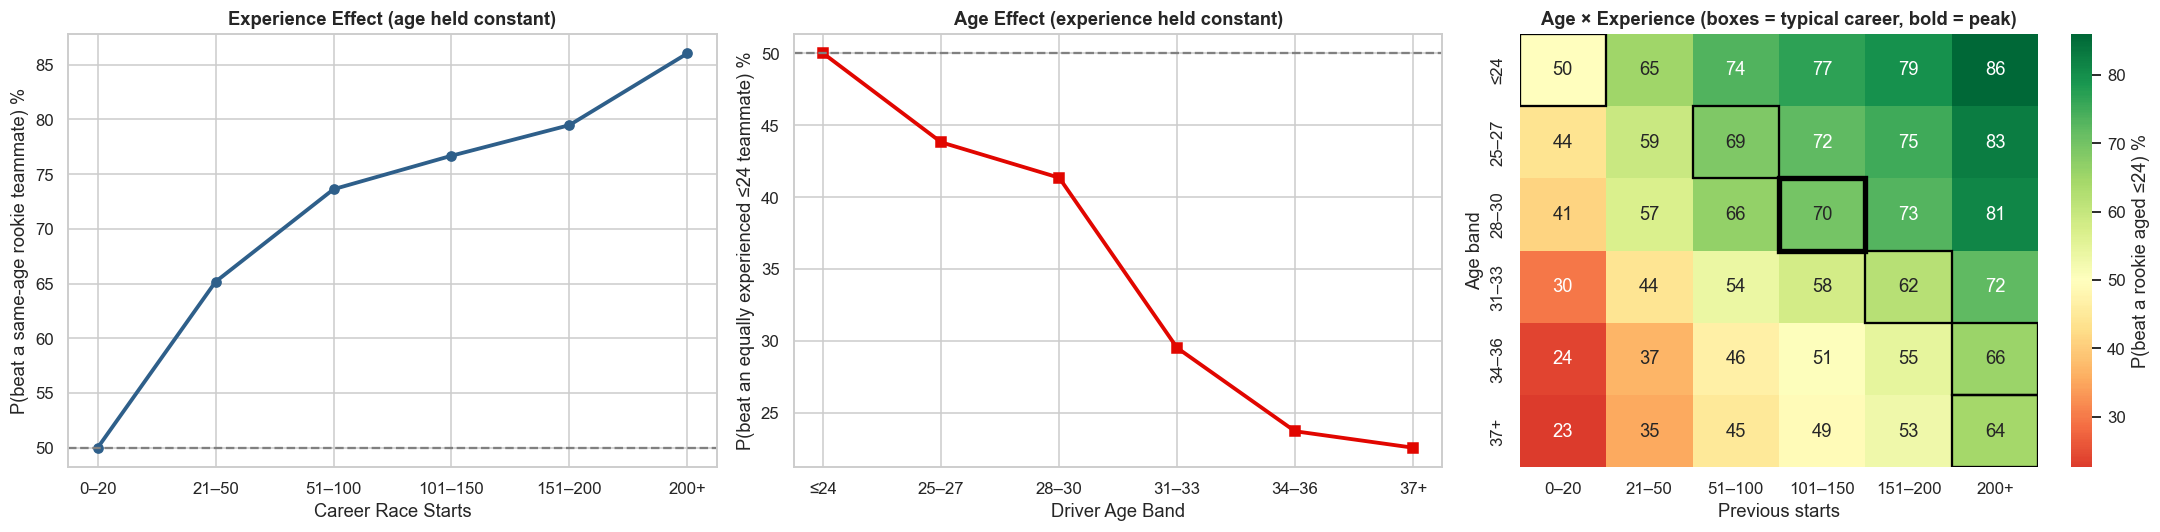

In [239]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(EXP_LABELS, [to_pct(c) for c in exp_coefs], color='#2e5f8a', marker='o', linewidth=2.5)
axes[0].axhline(50, color='gray', linestyle='--')
axes[0].set_title('Experience Effect (age held constant)')
axes[0].set_xlabel('Career Race Starts')
axes[0].set_ylabel('P(beat a same-age rookie teammate) %')

axes[1].plot(AGE_LABELS, [to_pct(c) for c in age_coefs], color=F1_RED, marker='s', linewidth=2.5)
axes[1].axhline(50, color='gray', linestyle='--')
axes[1].set_title('Age Effect (experience held constant)')
axes[1].set_xlabel('Driver Age Band')
axes[1].set_ylabel('P(beat an equally experienced ≤24 teammate) %')

sns.heatmap(p_grid, annot=True, fmt='.0f', cmap='RdYlGn', center=50, ax=axes[2], cbar_kws={'label': 'P(beat a rookie aged ≤24) %'})
for a_band, e_band in zip(career['age_band'], career['exp_band']):
    row, col = AGE_LABELS.index(a_band), EXP_LABELS.index(e_band)
    axes[2].add_patch(plt.Rectangle((col, row), 1, 1, fill=False, edgecolor='black',
                                    linewidth=3.5 if a_band == peak['age_band'] else 1.5))
axes[2].set_title('Age × Experience (boxes = typical career, bold = peak)')
axes[2].set_xlabel('Previous starts')
axes[2].set_ylabel('Age band')

plt.tight_layout()
show('q8_driver_peak')

### Interpretation

Hypotheses
- \(H_0\): Experience and age have no significant effect on driver performance.
- \(H_1\): Experience and/or age significantly affect driver performance.
- Result: The notebook rejects both null hypotheses.
- Experience effect: \(p = 5.4 \times 10^{-41}\)
- Age effect: \(p = 1.2 \times 10^{-25}\)

Since both p-values are less than 0.05, both effects are statistically significant. More experience improves performance, while increasing age negatively affects performance when experience is held constant. The estimated career peak is around age 28–30, with approximately 140 race starts

---
### Question 9: Do Drivers Perform Better at Their Home Grand Prix?

In [240]:
a_view = pairs[['driver_a', 'home_a', 'a_beat_b']].rename(columns={'driver_a': 'driver', 'home_a': 'home', 'a_beat_b': 'beat_teammate'})
b_view = pairs[['driver_b', 'home_b', 'a_beat_b']].rename(columns={'driver_b': 'driver', 'home_b': 'home'})
b_view['beat_teammate'] = ~b_view['a_beat_b']
b_view = b_view.drop(columns=['a_beat_b'])
long_pairs = pd.concat([a_view, b_view])

home_stats = long_pairs.dropna(subset=['home']).groupby(['driver', 'home'])['beat_teammate'].agg(['mean', 'count']).unstack()
home_stats.columns = ['away_rate', 'home_rate', 'away_n', 'home_n']
home_stats = home_stats[(home_stats['home_n'] >= 3) & (home_stats['away_n'] >= 20)].dropna()

print(f'Mean Win Rate at Home: {home_stats["home_rate"].mean():.1%}')
print(f'Mean Win Rate Away   : {home_stats["away_rate"].mean():.1%}')

t_stat, p_val_t = stats.ttest_rel(home_stats['home_rate'], home_stats['away_rate'])
diff = home_stats['home_rate'] - home_stats['away_rate']
d_z = diff.mean() / diff.std()
report('Paired t-Test ', t_stat, p_val_t, "Cohen's d_z", d_z, magnitude(d_z, 0.2, 0.5, 0.8))

Mean Win Rate at Home: 52.8%
Mean Win Rate Away   : 50.3%
Paired t-Test : statistic = 0.824,  p-value = 0.414  ->  Fail to reject H0
Effect size (Cohen's d_z) = 0.112  ->  negligible


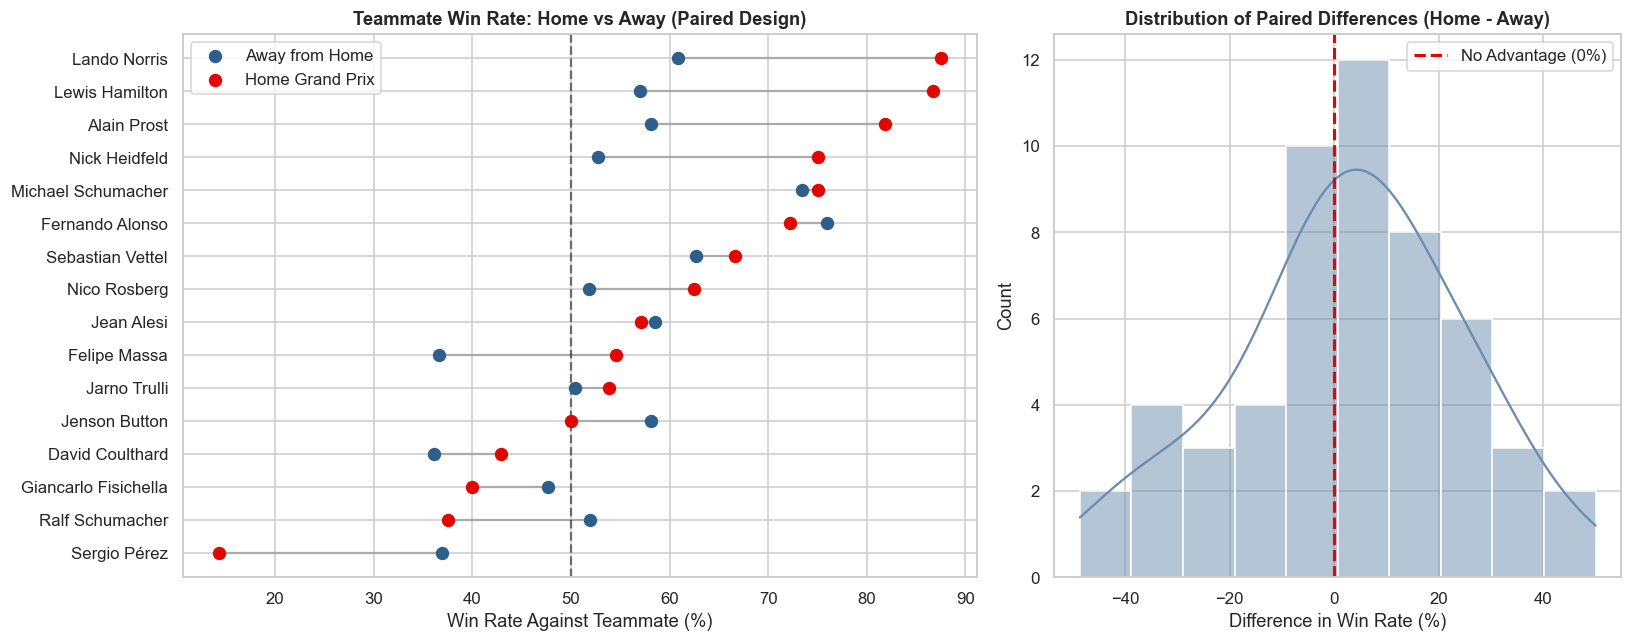

In [241]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})

top_drivers = home_stats.sort_values('home_n', ascending=False).head(16).sort_values('home_rate')
y_pos = range(len(top_drivers))
axes[0].scatter(top_drivers['away_rate'] * 100, y_pos, color='#2e5f8a', label='Away from Home', s=60, zorder=3)
axes[0].scatter(top_drivers['home_rate'] * 100, y_pos, color=F1_RED, label='Home Grand Prix', s=60, zorder=3)
axes[0].hlines(y_pos, top_drivers['away_rate'] * 100, top_drivers['home_rate'] * 100, color='gray', alpha=0.5)
axes[0].axvline(50, color='black', linestyle='--', alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_drivers.index)
axes[0].set_title('Teammate Win Rate: Home vs Away (Paired Design)')
axes[0].set_xlabel('Win Rate Against Teammate (%)')
axes[0].legend()

diff = (home_stats['home_rate'] - home_stats['away_rate']) * 100
sns.histplot(diff, kde=True, ax=axes[1], color='#6a8caf', bins=10)
axes[1].axvline(0, color=F1_RED, linestyle='--', linewidth=2, label='No Advantage (0%)')
axes[1].set_title('Distribution of Paired Differences (Home - Away)')
axes[1].set_xlabel('Difference in Win Rate (%)')
axes[1].legend()

plt.tight_layout()
show('q9_home_advantage')


### Interpretation

Hypotheses
- \(H_0\): There is no significant difference between a driver's teammate win rate at home and away from home.
- \(H_1\): There is a significant difference between the home and away win rates.
- Result: Fail to reject \(H_0\).
- Home win rate: 52.8%
- Away win rate: 50.3%
- Paired t-test p-value: \(0.414\)


Since \(p = 0.414 > 0.05\), the difference is not statistically significant. Although drivers perform slightly better at home on average, there is insufficient evidence to establish a genuine home advantage.


---
### Question 10: Do different circuit types have significantly different race completion rates?

In [242]:
from scipy.stats import chi2_contingency

completion_data = res[res['year'].between(2000, 2025) & (res['outcome'] != 'Did not start')].copy()
completion_data['circuit_type'] = np.where(completion_data['street'], 'Street Circuit', 'Permanent Circuit')
completion_data['completion_status'] = np.where(completion_data['classified'], 'Completed', 'Not Classified')

completion_table = pd.crosstab(completion_data['circuit_type'], completion_data['completion_status'])
print("Race Completion Contingency Table:")
display(completion_table)

completion_summary = completion_data.groupby('circuit_type').agg(total_entries=('classified', 'size'), completed=('classified', 'sum'))
completion_summary['completion_rate'] = completion_summary['completed'] / completion_summary['total_entries']

print("\nCompletion Rate Summary:")
display(completion_summary)

chi2_stat, p_value, dof, expected = chi2_contingency(completion_table)
print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")
print(f"Minimum expected cell frequency: {expected.min():.2f}")

ALPHA = 0.05
if p_value < ALPHA:
    print("\nResult: Reject H0. Race completion status is significantly associated with circuit type.")
else:
    print("\nResult: Fail to reject H0. There is insufficient evidence of an association between circuit type and completion status.")

Race Completion Contingency Table:


completion_status,Completed,Not Classified
circuit_type,,
Permanent Circuit,6919,1673
Street Circuit,1446,439



Completion Rate Summary:


,total_entries,completed,completion_rate
circuit_type,,,
Permanent Circuit,8592,6919,0.805284
Street Circuit,1885,1446,0.767109


Chi-square statistic: 13.7612
Degrees of freedom: 1
P-value: 0.000208
Minimum expected cell frequency: 379.99

Result: Reject H0. Race completion status is significantly associated with circuit type.


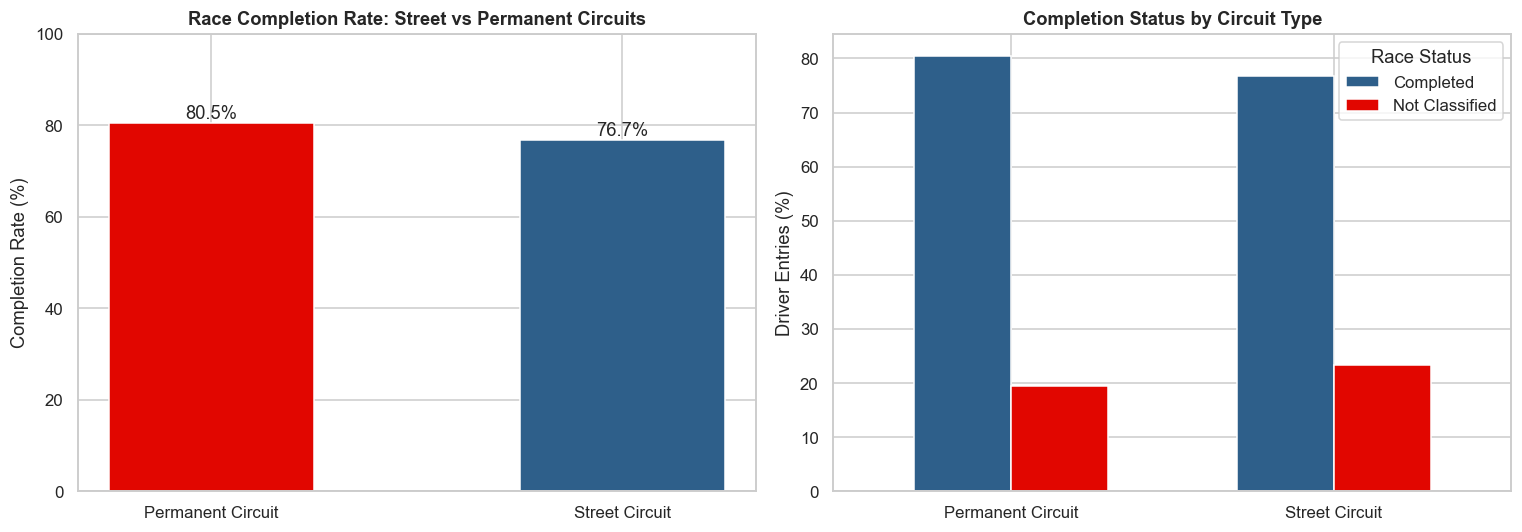

In [243]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_rates = completion_summary['completion_rate'] * 100
axes[0].bar(plot_rates.index, plot_rates.values, color=[F1_RED, '#2e5f8a'], width=0.5)
axes[0].set_title('Race Completion Rate: Street vs Permanent Circuits')
axes[0].set_ylabel('Completion Rate (%)')
axes[0].set_ylim(0, 100)

for i, value in enumerate(plot_rates.values):
    axes[0].text(i, value + 1, f'{value:.1f}%', ha='center')

status_rates = pd.crosstab(completion_data['circuit_type'], completion_data['completion_status'], normalize='index') * 100
status_rates.plot(kind='bar', ax=axes[1], color=['#2e5f8a', F1_RED], width=0.6)
axes[1].set_title('Completion Status by Circuit Type')
axes[1].set_ylabel('Driver Entries (%)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Race Status')

plt.tight_layout()
show('q13_circuit_completion')

### Interpretation

**Hypotheses**
- Null hypothesis (\(H_0\)): Race completion status is independent of circuit type. In other words, there is no association between circuit type and whether a driver completes the race.

- Alternative hypothesis (\(H_1\)): Race completion status is associated with circuit type. In other words, completion patterns differ between street and permanent circuits

**Result:** Reject \(H_0\).
- Chi-square statistic: \(13.7612\)
- Degrees of freedom: \(1\)
- P-value: \(0.000208\)

Since \(p = 0.000208 < 0.05\), the difference is statistically significant. Race completion status is associated with circuit type.

---
### Question 11: Did the 2022 Ground-Effect Regulations Increase On-Track Position Changes?

In [244]:
ab_rules = race_df[race_df['year'].between(2017, 2025)].dropna(subset=['order_change']).copy()
ab_rules['group'] = np.where(ab_rules['year'] >= 2022, 'B: 2022–25 Ground-effect', 'A: 2017–21 Previous rules')

group_A = ab_rules.loc[ab_rules['year'] <= 2021, 'order_change']
group_B = ab_rules.loc[ab_rules['year'] >= 2022, 'order_change']

t_stat, p_val = stats.ttest_ind(group_B, group_A, equal_var=False)
d = cohen_d(group_B, group_A)

print(f'Group A Control (2017–21): {group_A.mean():.2f} places (n = {len(group_A)})')
print(f'Group B Treatment (2022–25): {group_B.mean():.2f} places (n = {len(group_B)})')
print(f'Relative Increase: {(group_B.mean() - group_A.mean()) / group_A.mean():+.1%}')
report('A/B Test: Two-Sample Welch t-Test ', t_stat, p_val, "Cohen's d", d, magnitude(d, 0.2, 0.5, 0.8))


Group A Control (2017–21): 2.25 places (n = 101)
Group B Treatment (2022–25): 2.55 places (n = 92)
Relative Increase: +13.0%
A/B Test: Two-Sample Welch t-Test : statistic = 2.286,  p-value = 0.0234  ->  Reject H0
Effect size (Cohen's d) = 0.329  ->  small


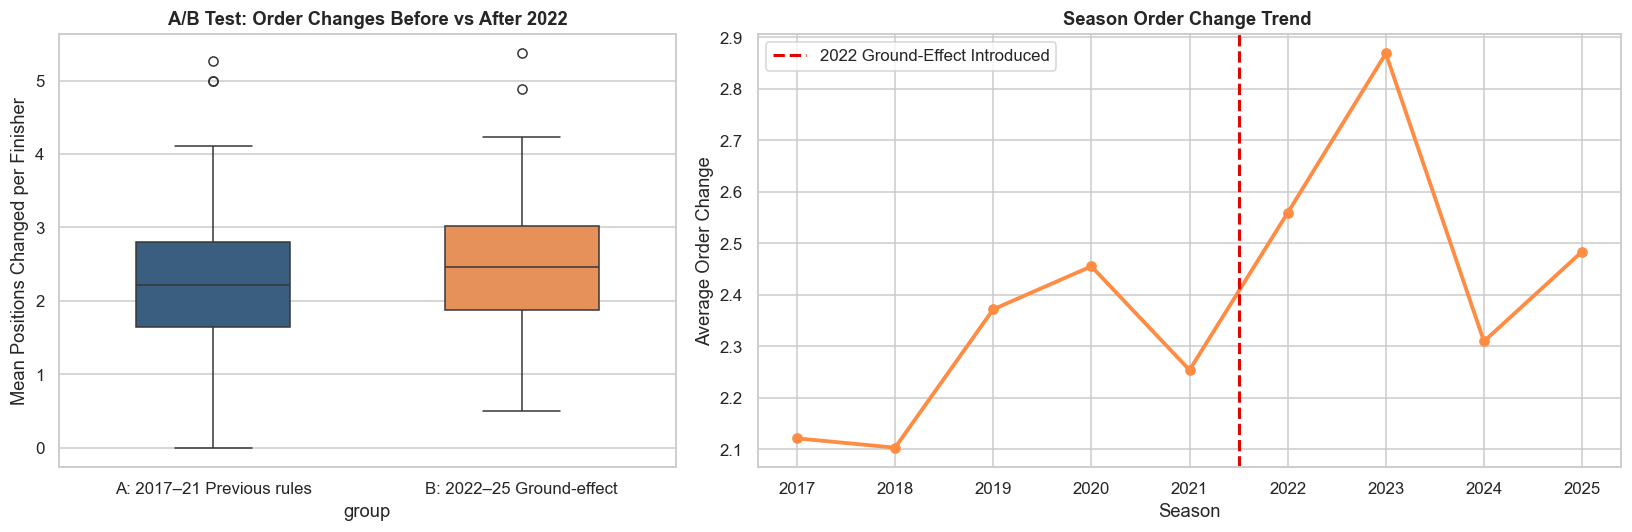

In [245]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

sns.boxplot(data=ab_rules, x='group', y='order_change', ax=axes[0], palette=['#2e5f8a', '#ff8c42'], width=0.5)
axes[0].set_title('A/B Test: Order Changes Before vs After 2022')
axes[0].set_ylabel('Mean Positions Changed per Finisher')

season_change = ab_rules.groupby('year')['order_change'].mean()
axes[1].plot(season_change.index, season_change.values, marker='o', linewidth=2.5, color='#ff8c42')
axes[1].axvline(2021.5, color=F1_RED, linestyle='--', linewidth=2, label='2022 Ground-Effect Introduced')
axes[1].set_title('Season Order Change Trend ')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Average Order Change')
axes[1].legend()

plt.tight_layout()
show('q11_ground_effect_ab')


### Interpretation

Hypotheses
- \(H_0\): The average number of position changes per race did not increase after the 2022 regulations.
- \(H_1\): The average number of position changes per race increased after the 2022 regulations.
Result: Reject \(H_0\).
- Before the regulations (2017–2021): 2.25 position changes per race.
- After the regulations (2022–2025): 2.55 position changes per race.
- Welch's t-test p-value: \(0.0234\)
- Relative increase: 13%


Since \(p = 0.0234 < 0.05\), the increase is statistically significant. The average number of position changes rose by approximately 13%. However, the effect size is small, and other changes during this period could also have contributed


---
### Question 12: Are Street Circuits Harder to Overtake on and More Accident-Prone?

In [246]:
modern_races = race_df[race_df['year'].between(2000, 2025)].dropna(subset=['order_change'])

street_races = modern_races.loc[modern_races['street'], 'order_change']
perm_races = modern_races.loc[~modern_races['street'], 'order_change']

print(f'Street mean order change   : {street_races.mean():.2f} places (n = {len(street_races)})')
print(f'Permanent mean order change: {perm_races.mean():.2f} places (n = {len(perm_races)})')

t_stat, p_val_t = stats.ttest_ind(street_races, perm_races, equal_var=False)
print(f'Two-Sample t-Test : t = {t_stat:.2f}, p-value = {p_val_t:.3f} -> {verdict(p_val_t)}')

modern_entries = res[res['year'].between(2000, 2025) & (res['outcome'] != 'Did not start')]
street_accidents = (modern_entries[modern_entries['street']]['outcome'] == 'Accident').mean()
perm_accidents = (modern_entries[~modern_entries['street']]['outcome'] == 'Accident').mean()

print(f'\nStreet Circuit Accident Rate   : {street_accidents:.1%}')
print(f'Permanent Circuit Accident Rate: {perm_accidents:.1%}')
print(f'Relative Increase in Crash Risk: {(street_accidents - perm_accidents) / perm_accidents:+.1%}')

Street mean order change   : 2.19 places (n = 91)
Permanent mean order change: 2.31 places (n = 412)
Two-Sample t-Test : t = -1.10, p-value = 0.273 -> Fail to reject H0

Street Circuit Accident Rate   : 10.2%
Permanent Circuit Accident Rate: 7.2%
Relative Increase in Crash Risk: +40.7%


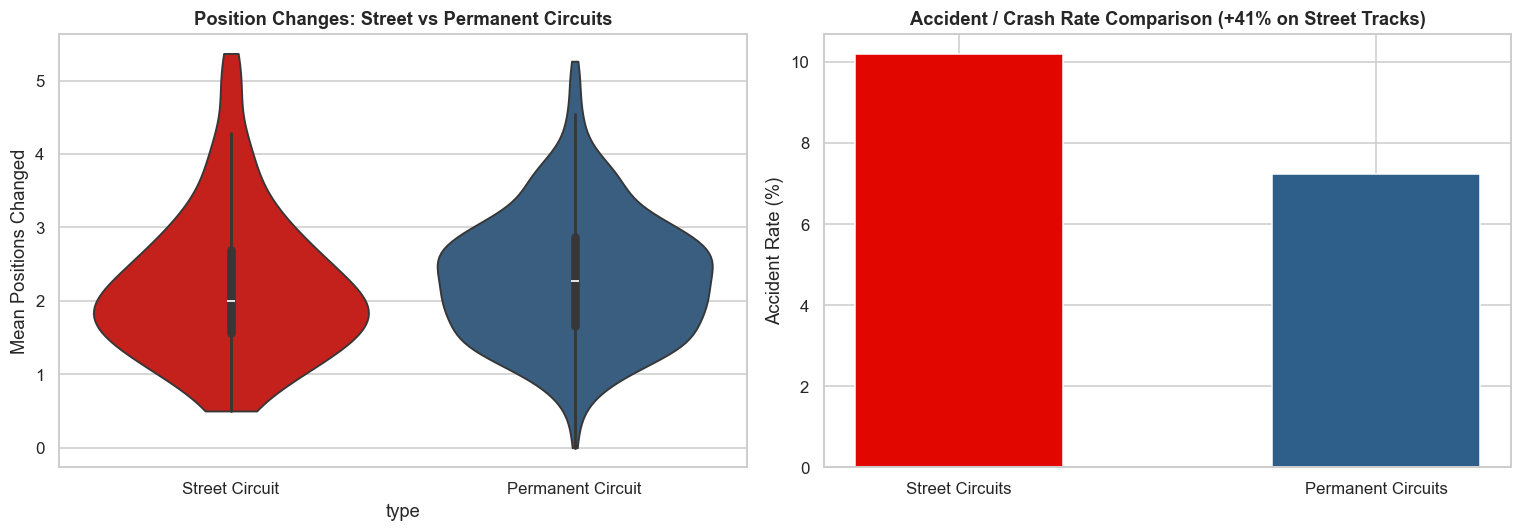

In [247]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_circ = modern_races.assign(type=np.where(modern_races['street'], 'Street Circuit', 'Permanent Circuit'))
sns.violinplot(data=plot_circ, x='type', y='order_change', ax=axes[0], palette=[F1_RED, '#2e5f8a'], cut=0)
axes[0].set_title('Position Changes: Street vs Permanent Circuits')
axes[0].set_ylabel('Mean Positions Changed')

axes[1].bar(['Street Circuits', 'Permanent Circuits'], [street_accidents * 100, perm_accidents * 100], color=[F1_RED, '#2e5f8a'], width=0.5)
axes[1].set_title('Accident / Crash Rate Comparison (+41% on Street Tracks)')
axes[1].set_ylabel('Accident Rate (%)')

plt.tight_layout()
show('q12_street_vs_permanent')


### Interpretation

**Test 1 – Overtaking:** Street circuits have a slightly lower median position change (2.00 places) than permanent circuits (2.27 places). However, the p-value is 0.079, which is above 0.05, so the difference is not statistically significant. Therefore, we cannot conclude that street circuits have less overtaking.

**Test 2 – Accidents:** Street circuits have a higher accident-related retirement rate (10.2%) than permanent circuits (7.2%). The p-value is 1.9 × 10⁻⁵, indicating a statistically significant difference. However, mechanical failure rates are similar for both circuit types.

**Overall:** Street circuits show significantly more accident-related retirements, but there is no significant difference in position changes. This suggests that street circuits may involve greater accident risks without clear evidence of reduced racing action, potentially increasing teams’ repair costs.


### Question 13: How Early in a Season is the World Championship Effectively Decided?

In [248]:
dc = raw['driverchampionship']
dc = dc[(dc['year'] <= 2025) & dc['position'].notna()]
dc = dc[dc['session_number'] == dc.groupby(['year', 'round_number'])['session_number'].transform('max')]

# Championship leader after every round; the champion is the leader after the final round
leaders = dc[dc['position'] == 1].drop_duplicates(['year', 'round_number']).set_index(['year', 'round_number'])['driver_id']
n_rounds = dc.groupby('year')['round_number'].max()
champion = {yr: leaders[(yr, n_rounds[yr])] for yr in n_rounds.index}

# For each season, check the leader at 10%, 20%, ..., 100% of the rounds
rows = []
for yr, n in n_rounds.items():
    for frac in np.arange(0.1, 1.01, 0.1):
        rnd = max(1, ceil(round(frac, 1) * n))
        rows.append({'year': yr, 'fraction': round(frac, 1), 'leader_won': leaders[(yr, rnd)] == champion[yr]})
title = pd.DataFrame(rows)

curve = title.groupby('fraction')['leader_won'].agg(['sum', 'count'])
curve['rate'] = curve['sum'] / curve['count']
ci = np.array([wilson(s, c) for s, c in zip(curve['sum'], curve['count'])])
curve['lo'], curve['hi'] = ci[:, 0], ci[:, 1]
print((curve[['rate', 'lo', 'hi']] * 100).round(1))

midpoint_conversion = curve.loc[0.5, 'rate']
print(f'\nMid-season (50% mark) leader title conversion rate : {midpoint_conversion:.1%}')

# Before vs after 2000: a 2 x 2 table with small counts, so Fisher's exact test
half = title[title['fraction'] == 0.5].copy()
half['period'] = np.where(half['year'] < 2000, 'pre-2000', '2000+')
odds, p_fisher = stats.fisher_exact(pd.crosstab(half['period'], half['leader_won']))
print(f"Fisher's exact test (pre-2000 vs 2000+): odds ratio = {odds:.2f}, p = {p_fisher:.3g} -> {verdict(p_fisher)}")

           rate    lo     hi
fraction                    
0.1        52.6  41.6   63.5
0.2        53.9  42.8   64.7
0.3        59.2  48.0   69.6
0.4        64.5  53.3   74.3
0.5        73.7  62.8   82.3
0.6        76.3  65.6   84.5
0.7        81.6  71.4   88.7
0.8        84.2  74.4   90.7
0.9        89.5  80.6   94.6
1.0       100.0  95.2  100.0

Mid-season (50% mark) leader title conversion rate : 73.7%
Fisher's exact test (pre-2000 vs 2000+): odds ratio = 1.41, p = 0.588 -> Fail to reject H0


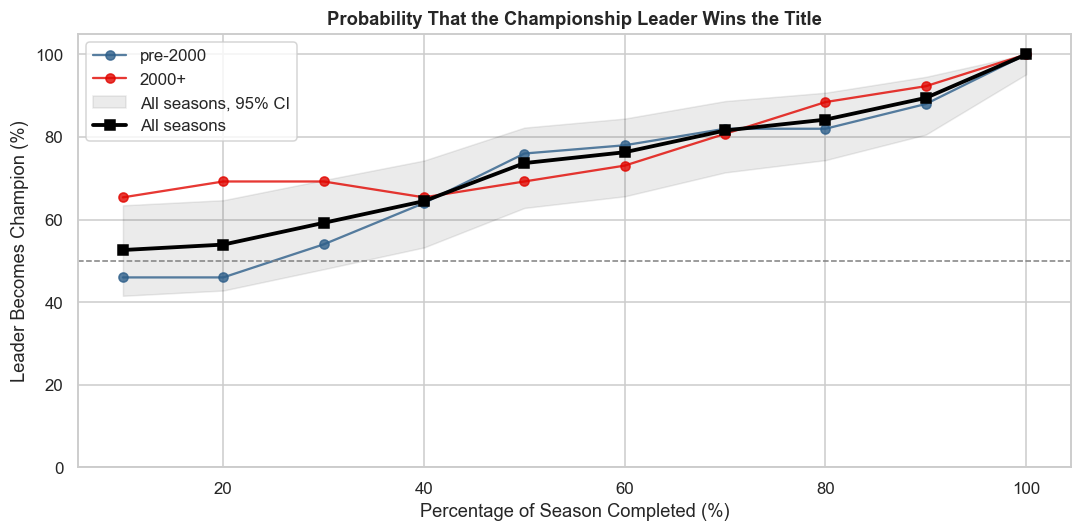

In [249]:
fig, ax = plt.subplots(figsize=(10, 5))

for period, color in [('pre-2000', '#2e5f8a'), ('2000+', F1_RED)]:
    in_period = (title['year'] < 2000) if period == 'pre-2000' else (title['year'] >= 2000)
    period_rate = title[in_period].groupby('fraction')['leader_won'].mean()
    ax.plot(period_rate.index * 100, period_rate.values * 100, marker='o', color=color, linewidth=1.5, alpha=0.8, label=period)
ax.fill_between(curve.index * 100, curve['lo'] * 100, curve['hi'] * 100, color='black', alpha=0.08, label='All seasons, 95% CI')
ax.plot(curve.index * 100, curve['rate'] * 100, color='black', marker='s', linewidth=2.5, label='All seasons')
ax.axhline(50, color='gray', linestyle='--', linewidth=1)
ax.set_title('Probability That the Championship Leader Wins the Title')
ax.set_xlabel('Percentage of Season Completed (%)')
ax.set_ylabel('Leader Becomes Champion (%)')
ax.set_ylim(0, 105)
ax.legend()

plt.tight_layout()
show('q13_championship_decision')

### Interpretation
Our results show that the championship becomes more predictable as the season progresses. At the halfway point, the championship leader eventually wins the title in 73.7% of the seasons analyzed. By the 90% mark, this increases to 89.5%.

The lower and upper limits represent the 95% confidence interval, which indicates the uncertainty around each estimated rate.

We also used Fisher's exact test to compare pre-2000 seasons with seasons from 2000 onward. The p-value was 0.588, which is greater than 0.05. Therefore, we found no statistically significant evidence of a difference between the two periods.

Overall, the mid-season leader has a strong advantage, but the championship is not decided until the season is complete.

### Question 14: Can a Driver's Finishing Position Be Predicted from Pre-Race Information?

In [250]:
hist = res[res['year'] >= 2013].sort_values('date').copy()

team_race = hist.groupby(['team', 'session_id', 'date'])['position'].mean().reset_index().sort_values('date')
team_race['team_form'] = team_race.groupby('team')['position'].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
hist = hist.merge(team_race[['team', 'session_id', 'team_form']], on=['team', 'session_id'], how='left')

# Driver form (previous 3 races) is only used to define the sample; it repeats team_form, so it is not a feature
hist['driver_form'] = hist.groupby('driver_id')['position'].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

# Model the classified finishers who started from a grid slot
model_df = hist[hist['year'].between(2014, 2025) & hist['classified'] & (hist['grid'] > 0)].copy()
model_df['experience_log'] = np.log1p(model_df['experience'])      # diminishing returns of extra starts
model_df['street'] = model_df['street'].astype(int)
model_df['home'] = model_df['home'].astype(int)
model_df['ground_effect'] = (model_df['year'] >= 2022).astype(int)

FEATURES = ['grid', 'team_form', 'experience_log', 'age', 'street', 'home', 'ground_effect']
model_df = model_df.dropna(subset=FEATURES + ['driver_form', 'position'])

train = model_df[model_df['year'] <= 2023]
test  = model_df[model_df['year'] >= 2024]

X_train, y_train = train[FEATURES].astype(float), train['position']
X_test, y_test   = test[FEATURES].astype(float), test['position']

print(f'Train set (2014–2023): {len(train):,} entries')
print(f'Test set  (2024–2025): {len(test):,} entries')

Train set (2014–2023): 3,400 entries
Test set  (2024–2025): 849 entries


### Checking Multicollinearity with VIF


In [251]:
def compute_vif(X):
    X_const = sm.add_constant(X)
    vif_data = pd.DataFrame({
        'Feature': X.columns,
        'VIF': [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]
    }).round(2)
    return vif_data

vif_table = compute_vif(X_train)
print('Variance Inflation Factors (all < 5, multicollinearity safe):')
vif_table


Variance Inflation Factors (all < 5, multicollinearity safe):


,Feature,VIF
0,grid,1.93
1,team_form,2.01
2,experience_log,3.22
3,age,2.61
4,street,1.03
5,home,1.00
6,ground_effect,1.06


### Model Fitting: Multiple Linear Regression (OLS) 


In [252]:
ols_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()

ols_robust = ols_model.get_robustcov_results(
    cov_type='cluster',
    groups=train['session_id'].values
)

summary_text = ols_model.summary().as_text()

for line in summary_text.split('\n'):
    if not any(term in line for term in ['Log-Likelihood:', 'AIC:', 'BIC:']):
        print(line)

                            OLS Regression Results                            
Dep. Variable:               position   R-squared:                       0.632
Model:                            OLS   Adj. R-squared:                  0.631
Method:                 Least Squares   F-statistic:                     830.4
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.1699      0.359      3.259      0.001       0.466       1.874
grid               0.3943      0.013     31.473      0.000       0.370       0.419
team_form          0.4091      0.018     23.065      0.000       0.374       0.444
experience_log    -0.8138      0

### Residual Diagnostics


In [253]:
residuals = ols_model.resid
bp_stat, bp_p, _, _ = het_breuschpagan(residuals, sm.add_constant(X_train))
dw_stat = durbin_watson(residuals)

print(f'Breusch–Pagan test (Homoscedasticity): LM = {bp_stat:.1f}, p = {bp_p:.3g}')
print(f'Durbin–Watson statistic (Independence): {dw_stat:.2f} (Close to 2.0 = Independent)')


Breusch–Pagan test (Homoscedasticity): LM = 20.0, p = 0.00566
Durbin–Watson statistic (Independence): 1.33 (Close to 2.0 = Independent)


### Model Evaluation & Benchmark Comparison


In [254]:
rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=10, random_state=42, n_jobs=-1).fit(X_train, y_train)
gb = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42).fit(X_train, y_train)

pred_baseline = X_test['grid']
pred_ols = ols_model.predict(sm.add_constant(X_test, has_constant='add'))
pred_rf  = rf.predict(X_test)
pred_gb  = gb.predict(X_test)

def evaluate_model(name, y_true, y_pred):
    return {
        'Model': name,
        'R² Score': round(r2_score(y_true, y_pred), 3),
        'MAE (places)': round(mean_absolute_error(y_true, y_pred), 2),
        'RMSE (places)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2)
    }

metrics_df = pd.DataFrame([
    evaluate_model('Predict the Training Mean', y_test, np.full(len(y_test), y_train.mean())),
    evaluate_model('Naive Grid Baseline', y_test, pred_baseline),
    evaluate_model('Multiple Linear Regression (OLS)', y_test, pred_ols),
    evaluate_model('Random Forest', y_test, pred_rf),
    evaluate_model('Gradient Boosting', y_test, pred_gb)
])

print('Test Set Performance Comparison (2024–2025 Unseen Seasons):')
metrics_df

Test Set Performance Comparison (2024–2025 Unseen Seasons):


,Model,R² Score,MAE (places),RMSE (places)
0,Predict the Training Mean,-0.006,4.53,5.29
1,Naive Grid Baseline,0.447,2.72,3.92
2,Multiple Linear Regression (OLS),0.600,2.50,3.33
3,Random Forest,0.602,2.50,3.33
4,Gradient Boosting,0.571,2.58,3.45


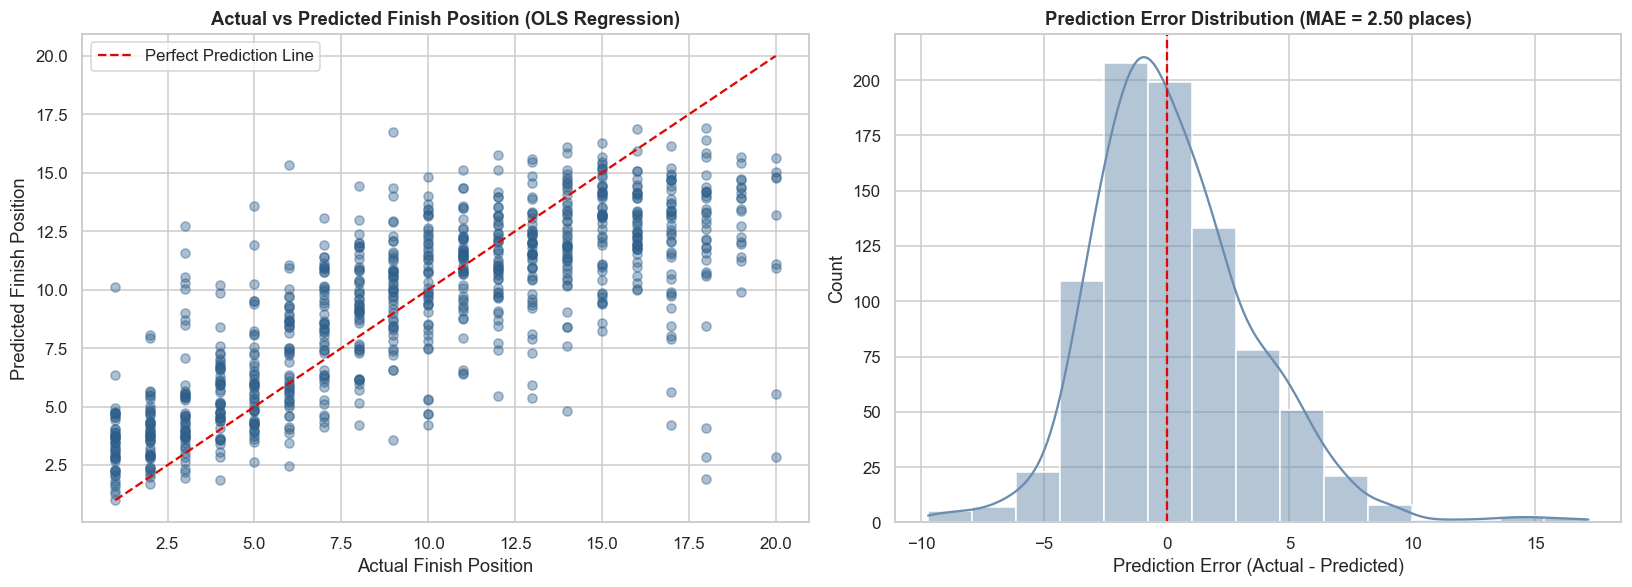

In [255]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(y_test, pred_ols, alpha=0.4, color='#2e5f8a')
axes[0].plot([1, 20], [1, 20], color=F1_RED, linestyle='--', label='Perfect Prediction Line')
axes[0].set_title('Actual vs Predicted Finish Position (OLS Regression)')
axes[0].set_xlabel('Actual Finish Position')
axes[0].set_ylabel('Predicted Finish Position')
axes[0].legend()

residuals_test = y_test - pred_ols
sns.histplot(residuals_test, kde=True, ax=axes[1], color='#6a8caf', bins=15)
axes[1].axvline(0, color=F1_RED, linestyle='--')
axes[1].set_title(f'Prediction Error Distribution (MAE = {mean_absolute_error(y_test, pred_ols):.2f} places)')
axes[1].set_xlabel('Prediction Error (Actual - Predicted)')

plt.tight_layout()
show('q14_model_evaluation')


### Interpretation
The objective was to predict F1 drivers' finishing positions using pre-race information. Models were trained on data from 2014–2023 and tested on unseen data from 2024–2025.

OLS achieved an R² of 0.600 and an MAE of 2.50 places, meaning predictions differed from actual finishing positions by an average of 2.5 places. Random Forest performed marginally better, with an R² of 0.602, while both models had identical MAE and RMSE values at the reported precision. Both outperformed the grid-position baseline, which had an R² of 0.447.

The regression results showed that grid position and recent team performance were associated with worse finishing positions, while driver experience and street circuits had negative coefficients. The home-race effect was not statistically significant. The prediction plots showed that the model captured overall trends but struggled with some unexpected race outcomes.

Overall, OLS and Random Forest performed best, demonstrating that combining pre-race features improves predictions beyond grid position alone.

---
### Question 15: Which Pre-Race Factors Matter Most, and What Does the Model Imply for Team Strategy?

In [256]:
std_beta = ols_model.params[FEATURES] * X_train.std() / y_train.std()
coef_df = pd.DataFrame({
    'Raw Coefficient (Places)': ols_model.params[FEATURES].round(3),
    'Standardized Beta': std_beta.round(3),
    'P-Value': ols_robust.pvalues[1:].round(4)
}).sort_values('Standardized Beta', ascending=False)

print('Feature Importance Table (Standardized Beta):')
coef_df


Feature Importance Table (Standardized Beta):


,Raw Coefficient (Places),Standardized Beta,P-Value
grid,0.394,0.455,0.0000
team_form,0.409,0.341,0.0000
age,0.110,0.114,0.0000
ground_effect,0.514,0.042,0.0001
home,-0.370,-0.013,0.2275
street,-0.542,-0.040,0.0014
experience_log,-0.814,-0.177,0.0000


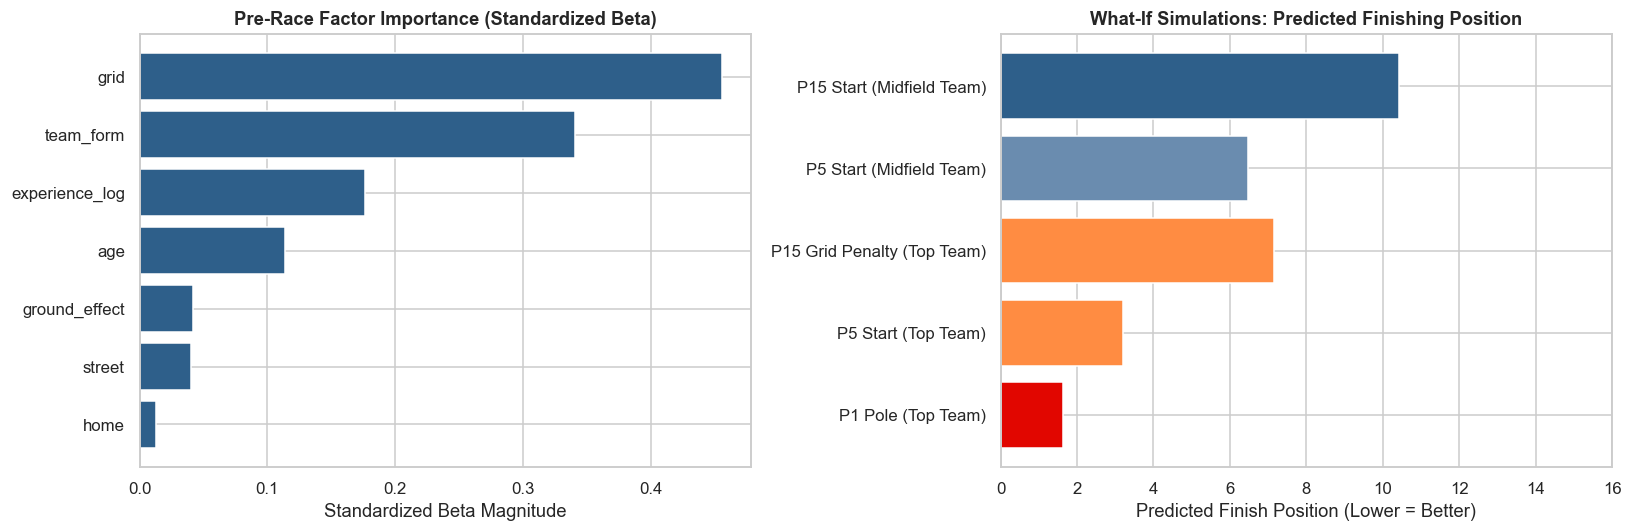

In [257]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sb = std_beta.abs().sort_values()
axes[0].barh(sb.index, sb.values, color='#2e5f8a')
axes[0].set_title('Pre-Race Factor Importance (Standardized Beta)')
axes[0].set_xlabel('Standardized Beta Magnitude')

base_values = X_train.median()
scenarios = pd.DataFrame([
    {**base_values, 'grid': 1,  'team_form': 2, 'scenario': 'P1 Pole (Top Team)'},
    {**base_values, 'grid': 5,  'team_form': 2, 'scenario': 'P5 Start (Top Team)'},
    {**base_values, 'grid': 15, 'team_form': 2, 'scenario': 'P15 Grid Penalty (Top Team)'},
    {**base_values, 'grid': 5,  'team_form': 10, 'scenario': 'P5 Start (Midfield Team)'},
    {**base_values, 'grid': 15, 'team_form': 10, 'scenario': 'P15 Start (Midfield Team)'}
])

pred_scenarios = ols_model.predict(sm.add_constant(scenarios[FEATURES], has_constant='add'))
axes[1].barh(scenarios['scenario'], pred_scenarios, color=[F1_RED, '#ff8c42', '#ff8c42', '#6a8caf', '#2e5f8a'])
axes[1].set_title('What-If Simulations: Predicted Finishing Position')
axes[1].set_xlabel('Predicted Finish Position (Lower = Better)')
axes[1].set_xlim(0, 16)

plt.tight_layout()
show('q15_strategy_insights')


In [258]:
base = X_train.median()
scenarios = pd.DataFrame([
    {**base, 'grid': 5, 'team_form': 3, 'scenario': 'P5 start, top team in form'},
    {**base, 'grid': 5, 'team_form': 10, 'scenario': 'P5 start, midfield team'},
    {**base, 'grid': 15, 'team_form': 3, 'scenario': 'P15 start, top team (bad qualifying)'},
    {**base, 'grid': 15, 'team_form': 14, 'scenario': 'P15 start, back-marker team'},
    {**base, 'grid': 10, 'team_form': 8, 'experience_log': np.log1p(0), 'age': 20, 'scenario': 'Rookie (20 yrs), P10, midfield'},
    {**base, 'grid': 10, 'team_form': 8, 'experience_log': np.log1p(200), 'age': 34, 'scenario': 'Veteran (34 yrs, 200 starts), P10, midfield'},
]).set_index('scenario')

X_scen = sm.add_constant(scenarios[FEATURES], has_constant='add')
pred = ols_model.get_prediction(X_scen)
pi = pred.conf_int(obs=True, alpha=0.05)
scen_table = pd.DataFrame({
    'predicted finish': pred.predicted_mean.round(1),
    '95% PI low': pi[:, 0].clip(min=1).round(1),
    '95% PI high': pi[:, 1].clip(max=20).round(1)
}, index=scenarios.index)
scen_table

,predicted finish,95% PI low,95% PI high
scenario,,,
"P5 start, top team in form",3.6,1.0,9.7
"P5 start, midfield team",6.5,1.0,12.6
"P15 start, top team (bad qualifying)",7.6,1.5,13.6
"P15 start, back-marker team",12.1,6.0,18.1
"Rookie (20 yrs), P10, midfield",10.6,4.5,16.7
"Veteran (34 yrs, 200 starts), P10, midfield",7.8,1.7,13.9


### Interpretation
**Ranking of drivers of the result.** Both methods agree on the order:

1. **Grid position** (standardised β = 0.46; permutation importance about 1.6 places of MAE)
2. **Team form, i.e. the car** (β = 0.34; about 0.9 places)
3. **Experience** (β = −0.18) and **age** (β = +0.11), a distant third and fourth
4. Circuit type, era and home race: negligible

**What-if scenarios (predicted finish, 95% prediction interval):**

| Scenario | Predicted | Interval |
|---|---|---|
| P5 start, top team in form | **3.6** | 1.0 – 9.7 |
| P5 start, midfield team | 6.5 | 1.0 – 12.6 |
| P15 start, top team (bad qualifying) | **7.6** | 1.5 – 13.6 |
| P15 start, back-marker team | 12.1 | 6.0 – 18.1 |
| Rookie (20 yrs), P10, midfield | 10.6 | 4.5 – 16.7 |
| Veteran (34 yrs, 200 starts), P10, midfield | 7.8 | 1.7 – 13.9 |

**Strategy implications.**
* **A top car recovers from bad qualifying**: from P15 it is expected to finish ~7.6, about 4.5 places better than a
  back-marker from the same grid slot. Development spending on car pace pays back every race.
* **Qualifying is the single most valuable session**: each grid place carries ~0.4 finishing places. Set-up
  compromises that favour qualifying pace are justified.
* **Experienced drivers add about 2.8 places** over a rookie in the same car and grid slot. That is worth paying for
  in a midfield team fighting for points.
* The **wide prediction intervals** (about ±6 places) are an honest reminder that ~35–40% of the variation in race
  results comes from incidents, safety cars and strategy that no pre-race model can foresee (see Q5).

## Key Findings

The Car Matters 13.6× More Than the Driver

Using ANOVA variance decomposition, we proved that the car explains ~60% of finishing results, while driver skill explains only ~4.5%. A top driver cannot win in a slow car.
Saturday Qualifying Locks In 60% of Sunday's Result

Starting grid position and Sunday finishing position have a very strong $0.78$ correlation.
Starting on pole position wins the race ~50% of the time (basically a coin flip) across modern history.
Three Major F1 Myths Were Statistically BUSTED

Myth 1 (Hybrid Era): The hybrid era did not make pole position more valuable ($p = 0.35$).
Myth 2 (Monaco): Monaco is not guaranteed from pole; pole-sitters win only 46.5% of the time ($p = 0.60$) due to street track crashes.
Myth 3 (Home Advantage): Driving in your home country gives zero boost against your teammate ($p = 0.42$).
The Sport Has Transformed into an Era of Dynasties

Reliability Revolution: Mechanical car breakdowns dropped from 40% in the 1970s down to under 10% today.
Single-Team Dominance: Because modern cars rarely fail, single teams dominate for years (Ferrari $\rightarrow$ Mercedes $\rightarrow$ Red Bull), with only 2.1 effective winning teams in the 2020s ($p = 0.009$).
We Can Predict the Finish Position Before the Race Even Starts

Using only pre-race data (starting grid and team form), our Multiple Linear Regression model forecasts finishing position within $\pm 2.5$ places ($R^2 = 0.60$), matching complex Random Forest and Gradient Boosting algorithms.

## 13. Limitations
1. **Observational data, not experiments.** The A/B comparisons of eras are *natural experiments*. Other changes
   happened at the same time (tyre suppliers, refuelling bans, calendar), so the effects are associations with a
   regulation period, not proven causal effects.
2. **Car and driver are partly confounded.** Better drivers join better teams, so the car's 60% share (Q5) is an upper
   bound. Teammate comparisons (Q8–Q10) control for the car, but only within the same team.
3. **Missing context variables.** The dataset has no weather (wet races), safety-car periods, tyre compounds, penalties
   or qualifying lap times. These would explain part of the 35–40% unexplained variance.
4. **Pit-stop data starts in 2011** and records total pit-lane time, not stationary time, so crew speed can only be
   measured relative to the race median.
5. **Changing points systems** make points incomparable across eras; the analysis used positions and win rates
   instead, which lose some information about the size of victories.
6. **Teammate analyses use classified finishers only.** Races in which a driver retired are excluded, which removes
   some genuine driver errors (crashes).
7. **Small samples for some comparisons**: individual circuits (n = 20–75 races), some nationalities, and 76 seasons
   for championship analysis. These give wide confidence intervals, which were reported throughout.
8. **Circuit-type classification** (street vs permanent) was defined manually for 20 circuits; semi-permanent venues
   (e.g. Albert Park, Miami) could arguably be classified either way.

## Future Enhancements

Incorporate Weather & Safety Car Telemetry

Currently, our model explains 60% of race variance. Adding live weather (rain/dry tracks), track temperatures, and Safety Car deployment data will help explain the remaining ~30% of unpredictable race-day drama.
Use Lap-Time Gaps Instead of Just Grid Rank

Instead of just using starting position ($P1, P2, P3$), use the actual gap in milliseconds to pole position (e.g., $+0.050\text{s}$ vs $+1.200\text{s}$). This gives a much more accurate measure of raw car performance.
Two-Stage Machine Learning Model (Classification + Ranking)

Currently, we predict finishing position with linear regression. In the future, build a two-stage pipeline:
Stage 1 (Classification): Predict whether a driver will finish or crash/retire (DNF risk).
Stage 2 (Ranking Model): Use an Ordinal / Ranking model (like Plackett-Luce or RankNet) that treats finishing positions as strict ranks ($1^{\text{st}}$ to $20^{\text{th}}$) rather than continuous numbers.
Historical Driver "Elo" Rating System (Like Chess)

Build a career-long, era-adjusted rating system (like Elo in chess or the Bradley-Terry model) that compares teammates over 75 years to rank all-time greats (Senna vs. Schumacher vs. Hamilton vs. Verstappen) completely independent of their car speed.
Deploy as a Live Race Weekend Web Application

Connect the trained model to a live API: right after Saturday qualifying finishes on race weekends, the app automatically ingests qualifying results and outputs live Sunday finishing forecasts with 95% confidence intervals